# Rock–Paper–Scissors with CNNs: from 100% test accuracy to a model that works on real photos

**Personal project** · A case study in generalization, distribution shift and honest evaluation · TensorFlow / Keras · Google Colab (T4 GPU)

The task looked simple: train an image classifier for the hand gestures *rock*, *paper* and *scissors* on the TensorFlow Datasets `rock_paper_scissors` dataset. The final model would be graded on a **secret hidden test set** that "may contain new people, backgrounds, lighting, cameras, distances and hand positions". Training on any additional data was allowed. The project began as a course challenge, and I extended it with real-world tests, robustness experiments and a browser game.

My first models reached 100% on validation and 80–95% on the public test set, and then recognised only 1–2 of 6 photos of a real hand. This notebook documents, step by step, what I tried, what failed, how I diagnosed each failure, and how the model was made to work on real photographs. Every experiment is kept, including the ones that did not work, and every prediction was written down before the experiment was run.

## Results at a glance

*Accuracy on held-out test sets, from this notebook's run (see section 20 for the full table and chart). "Own photos" were measured in my original run; the photos are private.*

| Model | Public test (372) | Real photos, new people (99) | HaGRID, 900 people | Hard angles (3,871) | HaGRID with shadow | Own photos* |
|---|---:|---:|---:|---:|---:|---:|
| Baseline CNN | 80.9% | — | — | — | — | 1 / 6 |
| CNN + augmentation | 94.6% | — | — | — | — | 2 / 6 |
| MobileNetV2, fine-tuned | 82.0% | — | — | — | — | 2 / 6 |
| + background randomization (no real photos) | 73.9% | 67.7% | — | — | — | 2 / 6 |
| + real photos (4,955 images) | 100.0% | 99.0% | 95.3% | 91.2% | 78.3% | 9 / 15 · 60% of 80 |
| Smaller set (2,400 images) | 100.0% | 98.0% | 93.2% | 89.2% | 76.7% | 10 / 15 · 64% of 80 |
| Smaller set + shadow training | 99.7% | 94.9% | 94.8% | 92.9% | 79.3% | 12 / 15 · 66% of 80 |
| **Smaller set + shadow training + own photos (final)**† | **100.0%** | **99.0%** | **97.8%** | **94.8%** | **86.0%** | used for training |

†Trained later, on private photos, and measured against the saved models from my original run. Small + shadows scored 96.0%, 95.9%, 93.1% and 82.9% in that comparison. It had no same-session control (section 17).

*On the instructor's test set of 262 student photos (section 18), measured with the saved models from my original run, the three candidates scored 89.7%, 86.6% and 88.9%. The best model there, small + shadows + own photos, scored 92.4%.*

**What made the difference**

1. **Testing on real photos early.** The public test set comes from the same computer-generated images as the training set, so it could not reveal that the models failed on real hands.
2. **Real training data beat clever augmentation.** Background randomization and zoom augmentation did not fix real photos; adding real photographs of many people did.
3. **Targeted fixes from measured weaknesses.** Changing one property of the test pictures at a time showed that shadows were the largest remaining weakness; training with random shadows reduced it, at a small cost on one real-photo test set.
4. **Control runs and paired tests.** The same code trained twice can differ by one to several points, so decisions were based on paired comparisons, sign tests and control runs, not on single numbers.
5. **One result is not proof.** Training on my own photos first made the model worse on everyone else's photos. A later retrain came out better, so the effect is still unresolved.

**Tools:** TensorFlow/Keras 3, MobileNetV2 transfer learning, `tf.data` pipelines, data augmentation, background compositing, public datasets (TFDS, GitHub, Kaggle, Hugging Face), scikit-learn metrics, SciPy sign tests.

## How to run this notebook

* **Runtime:** Runtime → Change runtime type → **T4 GPU**, then Runtime → Run all. A full run takes about an hour and downloads about 1.5 GB of public data.
* **Results vary between runs.** Training uses random numbers (seed 42), but GPU kernels and library versions still change results, usually by one or two percentage points and sometimes by much more (section 9). Where my original run differed, both numbers are given.
* **Optional: own photos.** Sections 8, 16 and 17 use my own hand photos, which are private and not included. To use your own, upload `own_photos.zip` in the Files panel before running. The zip contains one folder per photo set, each with `rock`, `paper` and `scissors` subfolders. A set named `train` is used for training in section 17; every other set is a test set. Without the zip these sections are skipped and the results from my own run are reported in the text.

## Contents

| # | Section | Question |
|---:|---|---|
| 1 | Setup | |
| 2 | The dataset | What does the data look like? |
| 3 | Baseline CNN | How well does a simple CNN do? |
| 4 | Architecture experiment | Does global average pooling generalize better? |
| 5 | Data augmentation | Does variety in training data help? |
| 6 | Transfer learning | Do pretrained features help? |
| 7 | Error analysis | What does the best model get wrong? |
| 8 | Reality check | Do the models work on real photos? |
| 9 | Background randomization | Is the white background the problem? |
| 10 | Zoom augmentation | Is the hand size the problem? |
| 11 | Real training photos | Does real data fix it? |
| 12 | Smaller training set | Is half the data enough? |
| 13 | Real-world test (HaGRID) | Does it work on 900 new people in their own rooms? |
| 14 | Hard cases | What are the remaining weaknesses? |
| 15 | Shadow training | Can I fix the biggest weakness? |
| 16 | Own photos | An independent check |
| 17 | Training on own photos | Does it help to add my own photos? |
| 18 | Instructor's test photos | How do the models do on a test set I did not build? |
| 19 | Deployment check | Will the saved model work for someone else? |
| 20 | Final results and lessons | |
| 21 | Project log | What happened, what went wrong and how the data changed |

## 1. Setup

On the Colab image used for this project, `import tensorflow_datasets` failed: the preinstalled `tensorflow-metadata` was built for a newer protobuf than Colab ships. Installing an older `tensorflow-metadata` (without touching TensorFlow or protobuf) fixes it. *Downgrading protobuf, the first fix I tried, breaks TensorFlow.*

In [ ]:
!pip install -q --no-deps "tensorflow-metadata==1.17.2"
!pip install -q importlib_resources

import sys, os, io, glob, json, time, hashlib, random, zipfile, subprocess
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
import google.protobuf
from tensorflow.keras import layers
from PIL import Image, ImageOps
from sklearn.metrics import confusion_matrix, classification_report
from scipy.stats import binomtest

print("python", sys.version.split()[0], "| tensorflow", tf.__version__, "| protobuf", google.protobuf.__version__, "| tfds", tfds.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

SEED, BATCH_SIZE, IMG_SIZE = 42, 32, 224
CLASS_NAMES = ['rock', 'paper', 'scissors']
tf.keras.utils.set_random_seed(SEED)

python 3.13.15 | tensorflow 2.21.0 | protobuf 6.33.6 | tfds 4.9.10
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Helper functions used throughout: evaluation of several models on several test sets, a paired comparison of two models with a sign test, a confusion-matrix plot, and loading of the optional own photos.

In [ ]:
RESULTS = {}   # model name -> {test set name -> accuracy}; collected for the final overview

def evaluate_sets(models, test_sets, record=True):
    """Accuracy of every model on every test set; returns the predicted classes."""
    preds = {}
    print(f"{'test set':<36}" + ''.join(f'{name[:22]:>24}' for name in models))
    for set_name, (x, y) in test_sets.items():
        row = ''
        for name, model in models.items():
            p = model.predict(x, batch_size=64, verbose=0).argmax(1)
            preds[set_name, name] = p
            acc = float((p == y).mean())
            if record:
                RESULTS.setdefault(name, {})[set_name] = acc
            row += f'{acc:>24.1%}'
        print(f'{set_name:<36}{row}')
    return preds

def paired(preds, set_name, a, b, y):
    """Pictures only model a gets right, only model b gets right, and the sign-test p-value."""
    ra, rb = preds[set_name, a] == y, preds[set_name, b] == y
    k, m = int((ra & ~rb).sum()), int((rb & ~ra).sum())
    return k, m, (binomtest(k, k + m).pvalue if k + m else 1.0)

def print_paired(preds, test_sets, a, b):
    print(f"\nPaired comparison: {a} vs {b} (pictures only one of them gets right; sign test)")
    for set_name, (_, y) in test_sets.items():
        k, m, p = paired(preds, set_name, a, b, y)
        print(f"  {set_name:<36} only {a[:20]} right: {k:>4} | only {b[:20]} right: {m:>4} | p = {p:.3f}")

def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
    fig, ax = plt.subplots(figsize=(5, 4.2))
    ax.imshow(cm, cmap='Blues')
    ax.set_xticks(range(3)); ax.set_xticklabels(CLASS_NAMES); ax.set_yticks(range(3)); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel('Predicted class'); ax.set_ylabel('Actual class'); ax.set_title(title, fontsize=10)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=12, color='white' if cm[i, j] > cm.max() / 2 else 'black')
    plt.tight_layout(); plt.show()

def to_square(img, mode='whole photo', size=300):
    """'centre square': crop the middle square. 'whole photo': pad to a square by repeating the border (nothing cut off)."""
    if mode == 'centre square':
        side = min(img.size); left, top = (img.width - side) // 2, (img.height - side) // 2
        return np.array(img.crop((left, top, left + side, top + side)).resize((size, size)))
    arr = np.asarray(img); side = max(arr.shape[:2]); ph, pw = side - arr.shape[0], side - arr.shape[1]
    arr = np.pad(arr, ((ph // 2, ph - ph // 2), (pw // 2, pw - pw // 2), (0, 0)), mode='edge')
    return np.array(Image.fromarray(arr).resize((size, size)))

def load_own_sets(zip_name='own_photos.zip'):
    """Optional private photos: {set name: (list of PIL images, labels)}. Empty if the zip was not uploaded."""
    found = glob.glob(f'/content/**/{zip_name}', recursive=True)
    if not found:
        return {}
    root = '/content/own_photos'
    zipfile.ZipFile(found[0]).extractall(root)
    sets = {}
    for f in sorted(glob.glob(f'{root}/**/*', recursive=True)):
        if not f.lower().endswith(('.jpg', '.jpeg', '.png')):
            continue
        parts = os.path.relpath(f, root).split(os.sep)
        label = next((CLASS_NAMES.index(p.lower()) for p in parts[:-1] if p.lower() in CLASS_NAMES), None)
        if label is None:
            continue
        set_name = parts[0] if parts[0].lower() not in CLASS_NAMES else 'own'
        sets.setdefault(set_name, ([], []))
        sets[set_name][0].append(ImageOps.exif_transpose(Image.open(f)).convert('RGB'))
        sets[set_name][1].append(label)
    return {name: (imgs, np.array(labels)) for name, (imgs, labels) in sets.items()}

OWN_SETS = load_own_sets()
OWN_TEST = {name: s for name, s in OWN_SETS.items() if name != 'train'}
print("Own photo sets:", {name: len(s[1]) for name, s in OWN_SETS.items()} or "none uploaded (sections 8, 16 and 17 are skipped)")

def own_arrays(mode='centre square', size=300):
    return {f'own: {name} ({len(y)})': (np.stack([to_square(im, mode, size) for im in imgs]), y) for name, (imgs, y) in OWN_TEST.items()}

Own photo sets: none uploaded (sections 8, 16 and 17 are skipped)


## 2. The dataset

`rock_paper_scissors` from TensorFlow Datasets: 2,520 training and 372 test images of 300 × 300 RGB, perfectly balanced. Every image is a **computer-generated hand on a plain white background**. That matters later: a model can reach high accuracy here without ever having seen a real photo.

training images: 2520  per class [840, 840, 840]
test images:     372  per class [124, 124, 124]
image shape: (300, 300, 3) | chance level: 33.3%


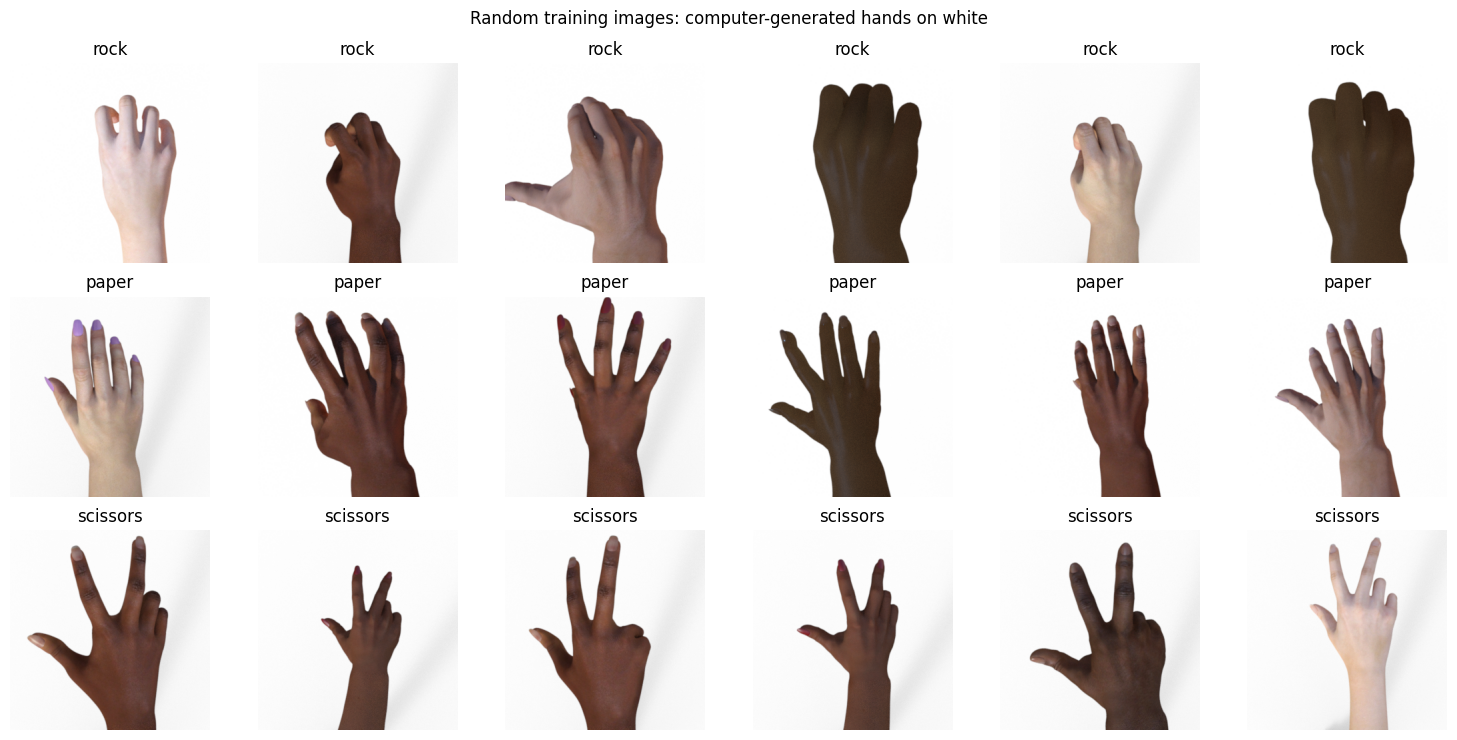

In [ ]:
(train_full, test_full), info = tfds.load('rock_paper_scissors', split=['train', 'test'], as_supervised=True, with_info=True)
assert info.features['label'].names == CLASS_NAMES
train_labels = np.array([int(l) for _, l in tfds.as_numpy(train_full)])
test_labels = np.array([int(l) for _, l in tfds.as_numpy(test_full)])
print(f"training images: {len(train_labels)}  per class {np.bincount(train_labels).tolist()}")
print(f"test images:     {len(test_labels)}  per class {np.bincount(test_labels).tolist()}")
print("image shape:", info.features['image'].shape, "| chance level: 33.3%")

shuffled = list(tfds.as_numpy(train_full.shuffle(len(train_labels), seed=SEED).take(200)))
fig, axes = plt.subplots(3, 6, figsize=(15, 7.5))
for row in range(3):
    for ax, img in zip(axes[row], [im for im, l in shuffled if l == row][:6]):
        ax.imshow(img); ax.set_title(CLASS_NAMES[row]); ax.axis('off')
plt.suptitle('Random training images: computer-generated hands on white'); plt.tight_layout(); plt.show()

## 3. Baseline CNN

**Split.** 85% of the official training split for training (2,142 images), 15% for validation (378). The 372 public test images are never used for training. Resizing and pixel scaling are layers inside the model, so the saved model accepts raw images.

**Model.** Two convolution blocks, `Flatten`, `Dense(128)`, softmax over 3 classes; Adam, sparse categorical cross-entropy, 10 epochs.

In [ ]:
tf.keras.utils.set_random_seed(SEED)
train_raw, val_raw, test_raw = tfds.load('rock_paper_scissors', split=['train[:85%]', 'train[85%:]', 'test'], as_supervised=True)
train_ds = train_raw.cache().shuffle(2200, seed=SEED).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_ds = val_raw.cache().batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_ds_b = test_raw.cache().batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

def as_arrays(ds):
    pairs = list(tfds.as_numpy(ds))
    return np.stack([a for a, _ in pairs]), np.array([int(l) for _, l in pairs])
cgi_val_x, cgi_val_y = as_arrays(val_raw)
cgi_test_x, cgi_test_y = as_arrays(test_raw)
print(f"train {int(len(train_labels) * 0.85)} | validation {len(cgi_val_y)} | public test {len(cgi_test_y)}")

def build_baseline():
    return tf.keras.Sequential([
        tf.keras.Input(shape=(300, 300, 3)),
        layers.Resizing(128, 128),
        layers.Rescaling(1.0 / 255),
        layers.Conv2D(32, 3, activation='relu'), layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation='relu'), layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(3, activation='softmax'),
    ], name='baseline_cnn')

def train_and_evaluate(model, epochs, train_data=None):
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    start = time.time()
    history = model.fit(train_data if train_data is not None else train_ds, validation_data=val_ds, epochs=epochs, verbose=2)
    val = history.history['val_accuracy']
    return history, {'parameters': model.count_params(), 'train_acc': history.history['accuracy'][-1],
                     'best_val_acc': max(val), 'public_test_acc': model.evaluate(test_ds_b, verbose=0)[1],
                     'seconds': time.time() - start}

EXPERIMENTS = {}
def show_experiments(names):
    print(f"\n{'model':<26}{'parameters':>12}{'train':>8}{'best val':>10}{'public test':>13}{'seconds':>9}")
    for n in names:
        r = EXPERIMENTS[n]
        print(f"{n:<26}{r['parameters']:>12,}{r['train_acc']:>8.1%}{r['best_val_acc']:>10.1%}{r['public_test_acc']:>13.1%}{r['seconds']:>9.0f}")
        RESULTS.setdefault(n, {})['public test (372)'] = r['public_test_acc']

baseline = build_baseline()
baseline_history, EXPERIMENTS['baseline CNN'] = train_and_evaluate(baseline, epochs=10)
show_experiments(['baseline CNN'])

train 2142 | validation 378 | public test 372
Epoch 1/10
67/67 - 36s - 536ms/step - accuracy: 0.8534 - loss: 0.4073 - val_accuracy: 0.9868 - val_loss: 0.0431
Epoch 2/10
67/67 - 1s - 20ms/step - accuracy: 0.9981 - loss: 0.0094 - val_accuracy: 1.0000 - val_loss: 0.0017
Epoch 3/10
67/67 - 1s - 19ms/step - accuracy: 1.0000 - loss: 0.0010 - val_accuracy: 1.0000 - val_loss: 5.4445e-04
Epoch 4/10
67/67 - 3s - 39ms/step - accuracy: 1.0000 - loss: 3.5671e-04 - val_accuracy: 1.0000 - val_loss: 3.0224e-04
Epoch 5/10
67/67 - 3s - 38ms/step - accuracy: 1.0000 - loss: 2.0719e-04 - val_accuracy: 1.0000 - val_loss: 2.0737e-04
Epoch 6/10
67/67 - 1s - 20ms/step - accuracy: 1.0000 - loss: 1.4678e-04 - val_accuracy: 1.0000 - val_loss: 1.6211e-04
Epoch 7/10
67/67 - 1s - 20ms/step - accuracy: 1.0000 - loss: 1.0937e-04 - val_accuracy: 1.0000 - val_loss: 1.2169e-04
Epoch 8/10
67/67 - 1s - 19ms/step - accuracy: 1.0000 - loss: 8.3660e-05 - val_accuracy: 1.0000 - val_loss: 9.5252e-05
Epoch 9/10
67/67 - 1s - 19ms

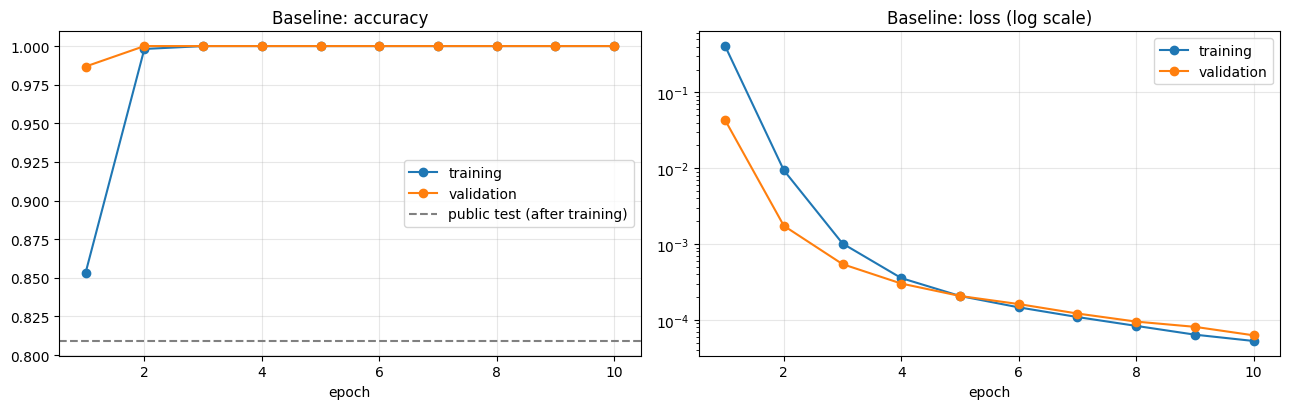

public test, rock      88.7%
public test, paper     91.1%
public test, scissors  62.9%


In [ ]:
h = baseline_history.history
epochs = range(1, len(h['accuracy']) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
ax1.plot(epochs, h['accuracy'], marker='o', label='training'); ax1.plot(epochs, h['val_accuracy'], marker='o', label='validation')
ax1.axhline(EXPERIMENTS['baseline CNN']['public_test_acc'], color='gray', linestyle='--', label='public test (after training)')
ax1.set_title('Baseline: accuracy'); ax1.set_xlabel('epoch'); ax1.legend(); ax1.grid(alpha=0.3)
ax2.plot(epochs, h['loss'], marker='o', label='training'); ax2.plot(epochs, h['val_loss'], marker='o', label='validation')
ax2.set_yscale('log'); ax2.set_title('Baseline: loss (log scale)'); ax2.set_xlabel('epoch'); ax2.legend(); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

pred = baseline.predict(cgi_test_x, verbose=0).argmax(1)
for c in range(3):
    print(f"public test, {CLASS_NAMES[c]:<9} {(pred[cgi_test_y == c] == c).mean():.1%}")

**Analysis.** 100% training and 100% validation accuracy, but only **80.9%** on the public test set (83.3% in my original run). Per class: rock 88.7%, paper 91.1%, scissors only 62.9%.

The learning curves look like a perfect fit, yet the public test score is much lower. The validation set is a random slice of the same computer-generated images as the training set, so it cannot reveal this gap. **The model memorised the training hands.** 7.37 million of its 7.39 million parameters sit in the single dense layer after `Flatten`.

## 4. Architecture experiment: `Flatten` → global average pooling

**Idea.** 99.7% of the baseline's parameters are in the dense layer after `Flatten`. Replacing `Flatten` with `GlobalAveragePooling2D` cuts the parameters from 7.39M to 28k, which should stop memorisation. Nothing else changes.

**Prediction (written before running):** validation accuracy decreases slightly, public test accuracy increases.

In [ ]:
def build_gap_cnn():
    return tf.keras.Sequential([
        tf.keras.Input(shape=(300, 300, 3)),
        layers.Resizing(128, 128), layers.Rescaling(1.0 / 255),
        layers.Conv2D(32, 3, activation='relu'), layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation='relu'), layers.MaxPooling2D(),
        layers.GlobalAveragePooling2D(),            # the only change (was Flatten)
        layers.Dense(128, activation='relu'),
        layers.Dense(3, activation='softmax'),
    ], name='gap_cnn')

tf.keras.utils.set_random_seed(SEED)
gap_cnn = build_gap_cnn()
_, EXPERIMENTS['global average pooling'] = train_and_evaluate(gap_cnn, epochs=10)
show_experiments(['baseline CNN', 'global average pooling'])

Epoch 1/10
67/67 - 7s - 107ms/step - accuracy: 0.3408 - loss: 1.0997 - val_accuracy: 0.3333 - val_loss: 1.0954
Epoch 2/10
67/67 - 1s - 19ms/step - accuracy: 0.3819 - loss: 1.0871 - val_accuracy: 0.3333 - val_loss: 1.0926
Epoch 3/10
67/67 - 1s - 18ms/step - accuracy: 0.4622 - loss: 1.0351 - val_accuracy: 0.5794 - val_loss: 0.9360
Epoch 4/10
67/67 - 1s - 21ms/step - accuracy: 0.5962 - loss: 0.8646 - val_accuracy: 0.5661 - val_loss: 0.7786
Epoch 5/10
67/67 - 1s - 20ms/step - accuracy: 0.7003 - loss: 0.6738 - val_accuracy: 0.7354 - val_loss: 0.5877
Epoch 6/10
67/67 - 1s - 19ms/step - accuracy: 0.8399 - loss: 0.4985 - val_accuracy: 0.8915 - val_loss: 0.4178
Epoch 7/10
67/67 - 1s - 18ms/step - accuracy: 0.8473 - loss: 0.4558 - val_accuracy: 0.8333 - val_loss: 0.4401
Epoch 8/10
67/67 - 1s - 18ms/step - accuracy: 0.8838 - loss: 0.3589 - val_accuracy: 0.8995 - val_loss: 0.3439
Epoch 9/10
67/67 - 1s - 18ms/step - accuracy: 0.8978 - loss: 0.3264 - val_accuracy: 0.9206 - val_loss: 0.3061
Epoch 10/

**Analysis.** Training accuracy fell to 90.1% and validation to 92.1%, and the public test **collapsed from 80.9% to 51.3%** (original run: 46.5%). The model now underfits instead of memorising.

The prediction was wrong. After only two convolution layers each feature describes a tiny patch (an edge, a bit of skin). Averaging each feature map over the whole image throws away *where* those patches are, and the arrangement of the fingers is exactly what separates the three gestures. **Fewer parameters does not automatically mean better generalization.** The change is rejected.

## 5. Data augmentation

**Idea.** Show the model a slightly different version of every training image in every epoch: random flip, rotation (±36°), zoom (±20%), shift (±10%), brightness and contrast. Memorising exact pixels then no longer works. Same architecture as the baseline; 25 epochs, because augmented training converges more slowly.

**Prediction:** training accuracy drops below 100%, public test accuracy rises.

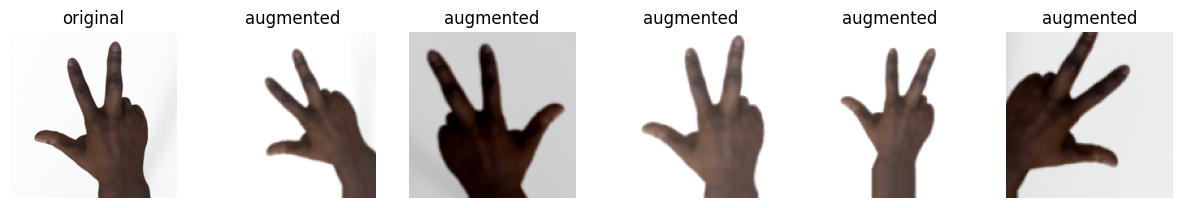

Epoch 1/25
67/67 - 7s - 98ms/step - accuracy: 0.5593 - loss: 1.0888 - val_accuracy: 0.8201 - val_loss: 0.4472
Epoch 2/25
67/67 - 3s - 38ms/step - accuracy: 0.8203 - loss: 0.4565 - val_accuracy: 0.9418 - val_loss: 0.2105
Epoch 3/25
67/67 - 2s - 24ms/step - accuracy: 0.8707 - loss: 0.3543 - val_accuracy: 0.9735 - val_loss: 0.1234
Epoch 4/25
67/67 - 2s - 24ms/step - accuracy: 0.9155 - loss: 0.2524 - val_accuracy: 0.9894 - val_loss: 0.0549
Epoch 5/25
67/67 - 2s - 28ms/step - accuracy: 0.9360 - loss: 0.1975 - val_accuracy: 0.9630 - val_loss: 0.1290
Epoch 6/25
67/67 - 2s - 26ms/step - accuracy: 0.9342 - loss: 0.1831 - val_accuracy: 0.9577 - val_loss: 0.1331
Epoch 7/25
67/67 - 2s - 25ms/step - accuracy: 0.9538 - loss: 0.1431 - val_accuracy: 0.9603 - val_loss: 0.0985
Epoch 8/25
67/67 - 2s - 24ms/step - accuracy: 0.9673 - loss: 0.1110 - val_accuracy: 1.0000 - val_loss: 0.0121
Epoch 9/25
67/67 - 2s - 24ms/step - accuracy: 0.9659 - loss: 0.1062 - val_accuracy: 0.9947 - val_loss: 0.0249
Epoch 10/2

In [ ]:
def build_augmented_cnn():
    return tf.keras.Sequential([
        tf.keras.Input(shape=(300, 300, 3)),
        layers.Resizing(128, 128), layers.Rescaling(1.0 / 255),
        layers.RandomFlip('horizontal'),
        layers.RandomRotation(0.1, fill_mode='nearest'),
        layers.RandomZoom(0.2, fill_mode='nearest'),
        layers.RandomTranslation(0.1, 0.1, fill_mode='nearest'),
        layers.RandomBrightness(0.2, value_range=(0.0, 1.0)),
        layers.RandomContrast(0.2),
        layers.Conv2D(32, 3, activation='relu'), layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation='relu'), layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(3, activation='softmax'),
    ], name='augmented_cnn')

preview = tf.keras.Sequential(build_augmented_cnn().layers[:8])
sample = next(iter(train_raw.batch(1)))[0]
fig, axes = plt.subplots(1, 6, figsize=(15, 2.8))
axes[0].imshow(sample[0]); axes[0].set_title('original')
for ax in axes[1:]:
    ax.imshow(np.clip(preview(sample, training=True)[0].numpy(), 0, 1)); ax.set_title('augmented')
for ax in axes: ax.axis('off')
plt.show()

tf.keras.utils.set_random_seed(SEED)
aug_cnn = build_augmented_cnn()
_, EXPERIMENTS['CNN + augmentation'] = train_and_evaluate(aug_cnn, epochs=25)
show_experiments(['baseline CNN', 'CNN + augmentation'])

**Analysis.** Training accuracy dropped slightly (98.4%) and the public test rose from 80.9% to **94.6%** (+13.7 points; original run: 83.3% → 90.1%). The prediction was correct.

Same architecture, same parameters: the improvement comes only from the variety of the training data.

## 6. Transfer learning with MobileNetV2

**Idea.** Use MobileNetV2 pretrained on ImageNet (1.3 million real photos) as the feature extractor, with a new head (global average pooling → dropout 0.2 → softmax).
* **Stage 1:** backbone frozen, learning rate 0.001, 8 epochs.
* **Stage 2:** unfreeze the backbone from layer 100, learning rate 0.00001, 8 epochs.

Images are resized to 224 × 224 and scaled to [−1, 1] inside the model.

**Prediction:** better than the best from-scratch model, because the features come from real photographs.

In [ ]:
def build_transfer_model():
    backbone = tf.keras.applications.MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights='imagenet')
    backbone.trainable = False
    inputs = tf.keras.Input(shape=(None, None, 3))
    x = layers.Resizing(IMG_SIZE, IMG_SIZE)(inputs)
    x = layers.RandomFlip('horizontal')(x)
    x = layers.RandomRotation(0.1, fill_mode='nearest')(x)
    x = layers.RandomZoom(0.2, fill_mode='nearest')(x)
    x = layers.RandomTranslation(0.1, 0.1, fill_mode='nearest')(x)
    x = layers.RandomBrightness(0.2)(x)
    x = layers.RandomContrast(0.2)(x)
    x = layers.Rescaling(1.0 / 127.5, offset=-1)(x)
    x = backbone(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(3, activation='softmax')(x)
    return tf.keras.Model(inputs, outputs, name='mobilenetv2_transfer'), backbone

def fine_tune(model, backbone, learning_rate):
    backbone.trainable = True
    for layer in backbone.layers[:100]:
        layer.trainable = False
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

def two_stage_record(model, hist_list, seconds):
    acc = sum((h.history['accuracy'] for h in hist_list), []); val = sum((h.history['val_accuracy'] for h in hist_list), [])
    return {'parameters': model.count_params(), 'train_acc': acc[-1], 'best_val_acc': max(val),
            'public_test_acc': model.evaluate(test_ds_b, verbose=0)[1], 'seconds': seconds}

tf.keras.utils.set_random_seed(SEED)
tl_model, tl_backbone = build_transfer_model()
tl_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
start = time.time()
tl_hist1 = tl_model.fit(train_ds, validation_data=val_ds, epochs=8, verbose=2)
EXPERIMENTS['MobileNetV2 frozen'] = two_stage_record(tl_model, [tl_hist1], time.time() - start)
tl_model.save('tl_frozen.keras')

fine_tune(tl_model, tl_backbone, 1e-5)
tl_hist2 = tl_model.fit(train_ds, validation_data=val_ds, epochs=8, verbose=2)
EXPERIMENTS['MobileNetV2 fine-tuned'] = two_stage_record(tl_model, [tl_hist1, tl_hist2], time.time() - start)
show_experiments(['baseline CNN', 'CNN + augmentation', 'MobileNetV2 frozen', 'MobileNetV2 fine-tuned'])

Epoch 1/8
67/67 - 12s - 175ms/step - accuracy: 0.8324 - loss: 0.4547 - val_accuracy: 0.9841 - val_loss: 0.1443
Epoch 2/8
67/67 - 4s - 66ms/step - accuracy: 0.9673 - loss: 0.1348 - val_accuracy: 0.9947 - val_loss: 0.0814
Epoch 3/8
67/67 - 4s - 64ms/step - accuracy: 0.9753 - loss: 0.1027 - val_accuracy: 0.9947 - val_loss: 0.0530
Epoch 4/8
67/67 - 4s - 65ms/step - accuracy: 0.9827 - loss: 0.0806 - val_accuracy: 0.9947 - val_loss: 0.0409
Epoch 5/8
67/67 - 4s - 66ms/step - accuracy: 0.9851 - loss: 0.0682 - val_accuracy: 0.9974 - val_loss: 0.0321
Epoch 6/8
67/67 - 4s - 64ms/step - accuracy: 0.9902 - loss: 0.0517 - val_accuracy: 0.9974 - val_loss: 0.0269
Epoch 7/8
67/67 - 4s - 66ms/step - accuracy: 0.9921 - loss: 0.0446 - val_accuracy: 1.0000 - val_loss: 0.0222
Epoch 8/8
67/67 - 4s - 65ms/step - accuracy: 0.9921 - loss: 0.0354 - val_accuracy: 1.0000 - val_loss: 0.0191
Epoch 1/8
67/67 - 21s - 316ms/step - accuracy: 0.8632 - loss: 0.3475 - val_accuracy: 0.9868 - val_loss: 0.0385
Epoch 2/8
67/67

**Analysis.** Frozen backbone **87.4%**, fine-tuned **82.0%** (the same in both runs). Both are below the augmented CNN (94.6%), and fine-tuning made it worse. The prediction was wrong.

On this public test set the pretrained features gave no clear advantage. The test set contains the same kind of computer-generated hands as the training set, which favours a model trained from scratch on exactly that style. 372 images is also small: 3 percentage points is about 11 images. **So the public test set cannot tell me which model is better on real photographs**, which is what the hidden set may contain.

## 7. Error analysis of the best from-scratch model

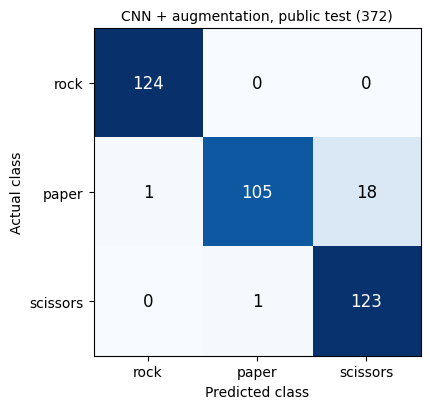

              precision    recall  f1-score   support

        rock      0.992     1.000     0.996       124
       paper      0.991     0.847     0.913       124
    scissors      0.872     0.992     0.928       124

    accuracy                          0.946       372
   macro avg      0.952     0.946     0.946       372
weighted avg      0.952     0.946     0.946       372



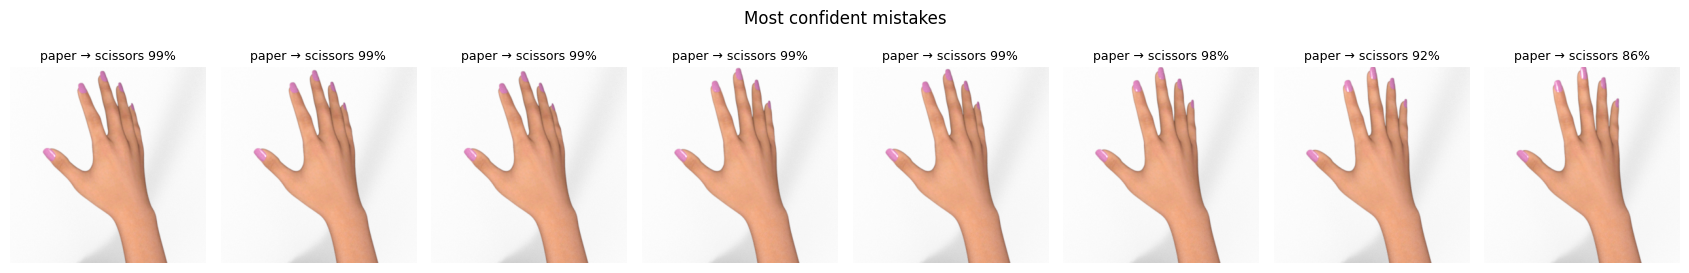

In [ ]:
pred = aug_cnn.predict(cgi_test_x, verbose=0)
plot_confusion(cgi_test_y, pred.argmax(1), 'CNN + augmentation, public test (372)')
print(classification_report(cgi_test_y, pred.argmax(1), target_names=CLASS_NAMES, digits=3))
wrong = np.where(pred.argmax(1) != cgi_test_y)[0]
wrong = wrong[np.argsort(-pred[wrong].max(1))][:8]
fig, axes = plt.subplots(1, 8, figsize=(17, 2.9))
for ax in axes: ax.axis('off')
for ax, i in zip(axes, wrong):
    ax.imshow(cgi_test_x[i]); ax.set_title(f"{CLASS_NAMES[cgi_test_y[i]]} → {CLASS_NAMES[pred[i].argmax()]} {pred[i].max():.0%}", fontsize=9)
plt.suptitle('Most confident mistakes'); plt.tight_layout(); plt.show()

**Analysis.** Rock is recognised perfectly (124 / 124). Of the 20 mistakes, 18 are **paper predicted as scissors** (paper recall 84.7%), most with high confidence. An open hand with spread fingers apparently looks like the V of scissors to a model that has seen only a few hand shapes. The same confusion comes back later on real photos.

## 8. Reality check: my own photos

The public test set is made of the same computer-generated hands as the training set. Before going further I photographed my own hands (rock, paper, scissors; close-ups in front of a laptop) and tested every model on them.

**Result in my original run (6 photos, 2 per gesture):**

| Model | Public test | Own photos |
|---|---:|---:|
| Baseline CNN | 83.3% | 1 / 6 |
| CNN + augmentation | 90.1% | 2 / 6 |
| MobileNetV2 frozen | 87.4% | 2 / 6 |
| MobileNetV2 fine-tuned | 82.0% | 2 / 6 |

Every model answered **"rock" for almost every photo, usually with close to 100% confidence**: chance level. This was the turning point of the project. Models that scored 82–90% on the public test set did not work on a real hand. This is **distribution shift**: the training and test images look alike, and real photos look different.

The cell below repeats this check if `own_photos.zip` was uploaded.

In [ ]:
if OWN_TEST:
    tl_frozen = tf.keras.models.load_model('tl_frozen.keras')
    early_models = {'baseline CNN': baseline, 'CNN + augmentation': aug_cnn, 'MobileNetV2 frozen': tl_frozen, 'MobileNetV2 fine-tuned': tl_model}
    evaluate_sets(early_models, own_arrays('centre square'))
else:
    print("No own photos uploaded: see the recorded result above.")

No own photos uploaded: see the recorded result above.


## 9. Background randomization

**Hypothesis.** Every training image has a plain white background, so the models never learned to separate a hand from a real scene.

**Change.**
1. Find the hand in each training image; the background is white/grey, the hand is coloured or dark.
2. Paste the hand onto a random background: usually a crop of an unrelated real photo from Imagenette, which is used only for backgrounds, never as labels. Sometimes use a plain colour, sometimes the original white.
3. Apply stronger geometric augmentation: any rotation, both flips, zoom ±30%, shifts ±15%.

The model is MobileNetV2 as in section 6, with a frozen stage and then fine-tuning.

**Prediction:** own-photo accuracy rises clearly above chance; public test accuracy stays in the same range.

*Engineering note: the first version computed the hand outlines on the fly and took 82 s per epoch. Computing each outline once and caching it brought this down to 9 s.*

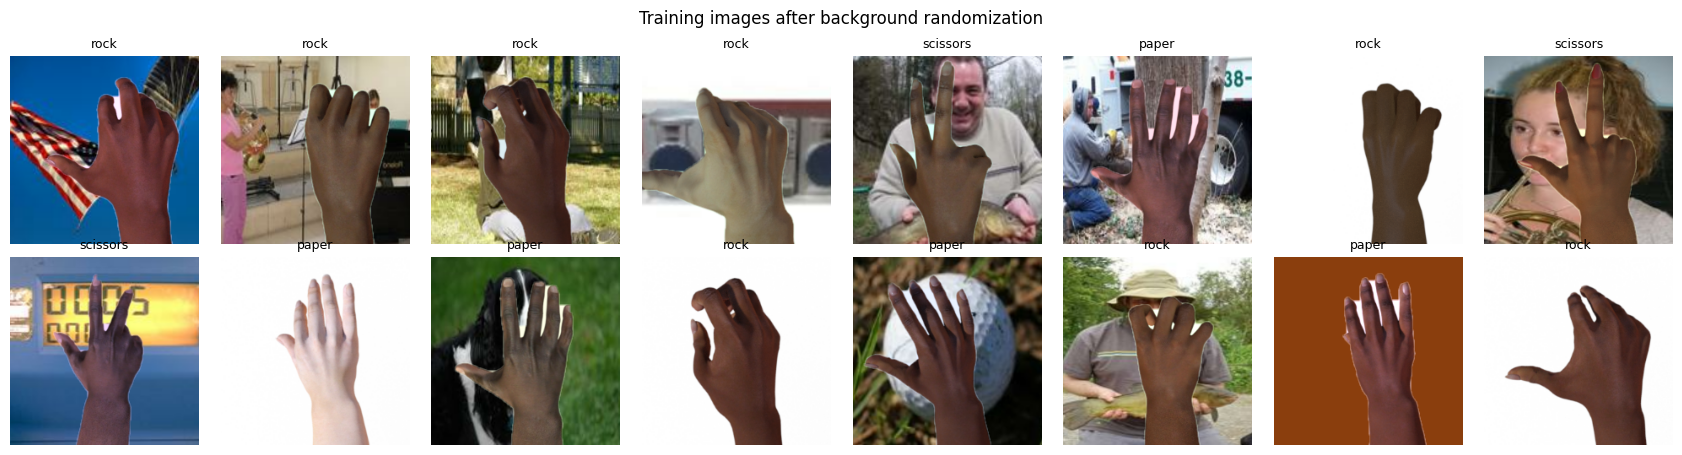

In [ ]:
BG_SIZE, N_BACKGROUNDS = 224, 1500
bg_raw = tfds.load('imagenette/160px-v2', split='train', as_supervised=True)

def load_background(img, _):
    return tf.cast(tf.image.resize(img, (256, 256)), tf.uint8)
def random_view(img):
    img = tf.image.random_crop(img, (BG_SIZE, BG_SIZE, 3))
    return tf.cast(tf.image.random_flip_left_right(img), tf.float32) / 255.0
bg_ds = (bg_raw.take(N_BACKGROUNDS).map(load_background, num_parallel_calls=tf.data.AUTOTUNE).cache()
         .shuffle(N_BACKGROUNDS, seed=SEED).repeat().map(random_view, num_parallel_calls=tf.data.AUTOTUNE))

def hand_and_mask(img, label):
    """Resize a training image and find the hand: mask 255 on the hand, 0 on the background."""
    img = tf.image.resize(img, (BG_SIZE, BG_SIZE))[tf.newaxis] / 255.0
    mx, mn = tf.reduce_max(img, axis=-1, keepdims=True), tf.reduce_min(img, axis=-1, keepdims=True)
    m = tf.cast(((mx - mn) > 0.08) | (mx < 0.50), tf.float32)    # coloured (skin) or dark = hand
    m = tf.nn.max_pool2d(m, 9, 1, 'SAME')                        # close holes
    m = -tf.nn.max_pool2d(-m, 9, 1, 'SAME')
    m = tf.nn.avg_pool2d(m, 3, 1, 'SAME')                        # soft edge
    return tf.cast(img[0] * 255.0, tf.uint8), tf.cast(m[0] * 255.0, tf.uint8), label

hands_ds = train_raw.map(hand_and_mask, num_parallel_calls=tf.data.AUTOTUNE).cache()   # outlines computed once

def random_background(imgs, masks, labels, bgs):
    imgs, masks = tf.cast(imgs, tf.float32) / 255.0, tf.cast(masks, tf.float32) / 255.0
    n = tf.shape(imgs)[0]
    r = tf.random.uniform([n, 1, 1, 1])
    plain = tf.random.uniform([n, 1, 1, 3]) + tf.zeros_like(imgs)
    bgs = tf.where(r < 0.30, plain, bgs[:n])                     # 15%: plain colour
    gain = tf.random.uniform([n, 1, 1, 3], 0.85, 1.15)           # small colour change of the hand
    out = masks * imgs * gain + (1.0 - masks) * bgs
    out = tf.where(r < 0.15, imgs, out)                          # 15%: original white background
    return tf.clip_by_value(out, 0.0, 1.0) * 255.0, labels

train_bg_ds = (tf.data.Dataset.zip((hands_ds.shuffle(2200, seed=SEED).batch(BATCH_SIZE), bg_ds.batch(BATCH_SIZE)))
               .map(lambda h, bgs: random_background(h[0], h[1], h[2], bgs), num_parallel_calls=tf.data.AUTOTUNE)
               .prefetch(tf.data.AUTOTUNE))

preview_x, preview_y = next(iter(train_bg_ds))
fig, axes = plt.subplots(2, 8, figsize=(17, 4.6))
for ax, img, lab in zip(axes.flat, preview_x, preview_y):
    ax.imshow(img.numpy().astype('uint8')); ax.set_title(CLASS_NAMES[int(lab)], fontsize=9); ax.axis('off')
plt.suptitle('Training images after background randomization'); plt.tight_layout(); plt.show()

In [ ]:
def build_robust_model(zoom=(-0.3, 0.3), shift=0.15, name='mobilenetv2_robust'):
    backbone = tf.keras.applications.MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights='imagenet')
    backbone.trainable = False
    inputs = tf.keras.Input(shape=(None, None, 3))
    x = layers.Resizing(IMG_SIZE, IMG_SIZE)(inputs)
    x = layers.RandomFlip('horizontal_and_vertical')(x)
    x = layers.RandomRotation(0.5, fill_mode='reflect')(x)
    x = layers.RandomZoom(zoom, fill_mode='reflect')(x)
    x = layers.RandomTranslation(shift, shift, fill_mode='reflect')(x)
    x = layers.RandomBrightness(0.25)(x)
    x = layers.RandomContrast(0.3)(x)
    x = layers.Rescaling(1.0 / 127.5, offset=-1)(x)
    x = backbone(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(3, activation='softmax')(x)
    return tf.keras.Model(inputs, outputs, name=name), backbone

tf.keras.utils.set_random_seed(SEED)
robust_model, robust_backbone = build_robust_model()
robust_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
start = time.time()
rb_hist1 = robust_model.fit(train_bg_ds, validation_data=val_ds, epochs=10, verbose=2)
fine_tune(robust_model, robust_backbone, 5e-5)
rb_hist2 = robust_model.fit(train_bg_ds, validation_data=val_ds, epochs=12, verbose=2)
EXPERIMENTS['background randomization'] = two_stage_record(robust_model, [rb_hist1, rb_hist2], time.time() - start)
show_experiments(['CNN + augmentation', 'MobileNetV2 fine-tuned', 'background randomization'])
if OWN_TEST:
    evaluate_sets({'background randomization': robust_model}, own_arrays('centre square'))

Epoch 1/10
67/67 - 17s - 250ms/step - accuracy: 0.5359 - loss: 1.0040 - val_accuracy: 0.8651 - val_loss: 0.5316
Epoch 2/10
67/67 - 10s - 148ms/step - accuracy: 0.7106 - loss: 0.7040 - val_accuracy: 0.8995 - val_loss: 0.3629
Epoch 3/10
67/67 - 11s - 164ms/step - accuracy: 0.7470 - loss: 0.5996 - val_accuracy: 0.9206 - val_loss: 0.2862
Epoch 4/10
67/67 - 11s - 162ms/step - accuracy: 0.7395 - loss: 0.6151 - val_accuracy: 0.9444 - val_loss: 0.2531
Epoch 5/10
67/67 - 20s - 302ms/step - accuracy: 0.7866 - loss: 0.5326 - val_accuracy: 0.9603 - val_loss: 0.2205
Epoch 6/10
67/67 - 10s - 143ms/step - accuracy: 0.7890 - loss: 0.5278 - val_accuracy: 0.9471 - val_loss: 0.2402
Epoch 7/10
67/67 - 11s - 167ms/step - accuracy: 0.7652 - loss: 0.5634 - val_accuracy: 0.9577 - val_loss: 0.2059
Epoch 8/10
67/67 - 20s - 302ms/step - accuracy: 0.7857 - loss: 0.5212 - val_accuracy: 0.9656 - val_loss: 0.1913
Epoch 9/10
67/67 - 11s - 162ms/step - accuracy: 0.8044 - loss: 0.4992 - val_accuracy: 0.9630 - val_loss:

**Analysis.** In this run the model reached only **73.9%** on the public test set; in my original run the same code reached 91.4%. A 17-point swing between two runs of identical code shows how unstable this model is on the computer-generated test set. Section 11 also measures it on real photos of new people: **67.7%**.

**In my original run the main prediction was wrong.** On my own photos the model still answered "rock" for every photo (2 / 6). The white background was not the main cause.

**Diagnosis.** I changed one property of my photos at a time and watched the predictions:
* Rotating, converting to grayscale and brightening changed almost nothing.
* Making the hand **smaller in the frame** changed the answers: a paper photo went from "rock" to "paper" with 76–98% confidence.

In the training images the hand is small, with the forearm visible. In my photos the hand fills the frame, and a large area of skin apparently looks like a fist to the model.

## 10. Zoom augmentation

**Change.** Same as section 9, plus much stronger zoom-in (the hand can become about 2.5 × larger and be cut off by the border) and larger shifts.

**Prediction:** own-photo accuracy rises; public test accuracy stays about the same.

In [ ]:
tf.keras.utils.set_random_seed(SEED)
zoom_model, zoom_backbone = build_robust_model(zoom=(-0.6, 0.3), shift=0.2, name='mobilenetv2_zoom')
zoom_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
start = time.time()
zm_hist1 = zoom_model.fit(train_bg_ds, validation_data=val_ds, epochs=6, verbose=2)
fine_tune(zoom_model, zoom_backbone, 5e-5)
zm_hist2 = zoom_model.fit(train_bg_ds, validation_data=val_ds, epochs=14, verbose=2)
EXPERIMENTS['background + strong zoom'] = two_stage_record(zoom_model, [zm_hist1, zm_hist2], time.time() - start)
show_experiments(['background randomization', 'background + strong zoom'])
if OWN_TEST:
    evaluate_sets({'background + strong zoom': zoom_model}, own_arrays('centre square'))

Epoch 1/6
67/67 - 16s - 245ms/step - accuracy: 0.5023 - loss: 1.0617 - val_accuracy: 0.8201 - val_loss: 0.5647
Epoch 2/6
67/67 - 11s - 158ms/step - accuracy: 0.6671 - loss: 0.7622 - val_accuracy: 0.8254 - val_loss: 0.4539
Epoch 3/6
67/67 - 10s - 142ms/step - accuracy: 0.7115 - loss: 0.6872 - val_accuracy: 0.9392 - val_loss: 0.2924
Epoch 4/6
67/67 - 11s - 163ms/step - accuracy: 0.7395 - loss: 0.6278 - val_accuracy: 0.9392 - val_loss: 0.2932
Epoch 5/6
67/67 - 11s - 158ms/step - accuracy: 0.7521 - loss: 0.6035 - val_accuracy: 0.9339 - val_loss: 0.2800
Epoch 6/6
67/67 - 11s - 166ms/step - accuracy: 0.7470 - loss: 0.6021 - val_accuracy: 0.9286 - val_loss: 0.2444
Epoch 1/14
67/67 - 24s - 352ms/step - accuracy: 0.7591 - loss: 0.5747 - val_accuracy: 0.9471 - val_loss: 0.1691
Epoch 2/14
67/67 - 20s - 296ms/step - accuracy: 0.8758 - loss: 0.3103 - val_accuracy: 0.9550 - val_loss: 0.1273
Epoch 3/14
67/67 - 12s - 176ms/step - accuracy: 0.9164 - loss: 0.2342 - val_accuracy: 0.9788 - val_loss: 0.074

**Analysis.** Public test **87.9%** in this run, up from 73.9% without the strong zoom. In my original run it went the other way (91.4% → 86.0%) and validation became unstable. Own-photo accuracy went from 2 / 6 to only 3 / 6, a single photo. The effect of zoom on the public test is not even stable in direction between runs. **Conclusion: augmentation of computer-generated images alone does not close the gap to real photos.** I stopped tuning against six photos, because that would only fit those six photos, the same mistake as tuning on a test set.

## 11. Adding real training photos

**Why.** The augmentation experiments showed that computer-generated images are not enough. Training on any data is allowed, so I add a modest number of real photos and keep the training set small.

| Source | Content | Training | Held out |
|---|---|---:|---:|
| TFDS `rock_paper_scissors` | computer-generated hands with random backgrounds | 2,142 | 378 validation, 372 public test |
| Giusti et al. 2018 (GitHub `alessandro-giusti/rock-paper-scissors`) | real photos taken by many students | groups D2, D4–D8 | D1, D3 as real validation; `testing` + D9 as real test |
| Kaggle `drgfreeman/rockpaperscissors` | real hands on a green background | 250 per class | 50 per class |

The real validation and test photos come from **different groups of people** than the training photos. During fine-tuning I keep the weights with the lowest loss on the real validation photos.

**Leakage check.** The Giusti dataset contains exact duplicate photos across folders. Every real test photo that also appears in the training photos is removed before testing.

**Prediction:** above 85% on real photos of new people; public test at least 88%.

Using Colab cache for faster access to the 'rockpaperscissors' dataset.
real training photos 2063 | green-screen training 750 | real validation 276
real test: 103 photos, of which 4 also appear in the training photos -> removed


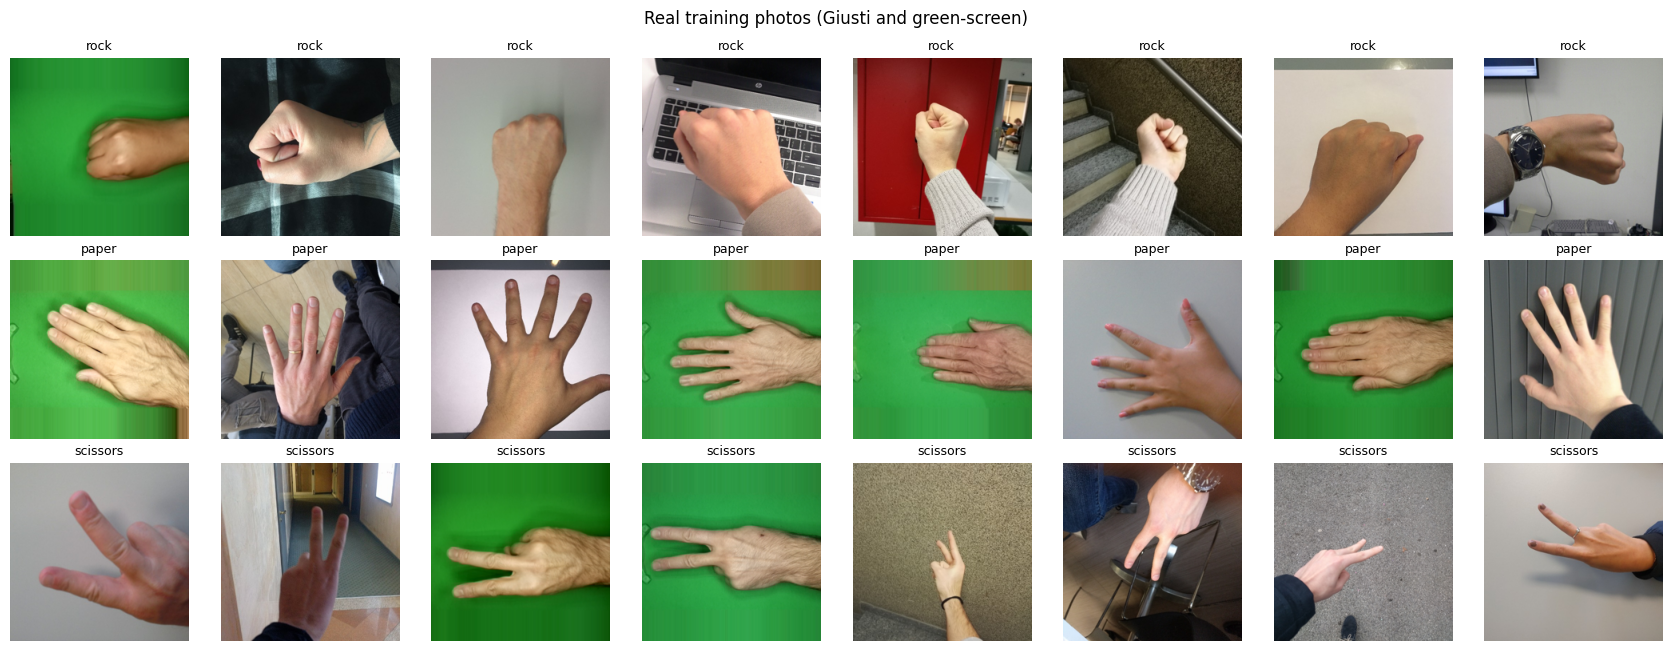

In [ ]:
GIUSTI_DIR = '/content/giusti_rps'
if not os.path.isdir(GIUSTI_DIR):
    subprocess.run(['git', 'clone', '-q', '--depth', '1', 'https://github.com/alessandro-giusti/rock-paper-scissors', GIUSTI_DIR], check=True)
import kagglehub
KAGGLE_DIR = kagglehub.dataset_download('drgfreeman/rockpaperscissors')

def load_image(path, mode, size=224):
    """mode 'crop': centre square. mode 'pad': pad to a square by repeating the border pixels."""
    img = ImageOps.exif_transpose(Image.open(path)).convert('RGB')
    return to_square(img, 'centre square' if mode == 'crop' else 'whole photo', size)

def giusti_items(groups):
    """Folders c0 / c1 / c2 = rock / paper / scissors."""
    return [(f, label) for g in groups for label in range(3)
            for f in sorted(glob.glob(f'{GIUSTI_DIR}/datasets/final/{g}/c{label}/*')) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

def load_set(items, mode):
    return np.stack([load_image(p, mode) for p, _ in items]), np.array([l for _, l in items])

real_train_x, real_train_y = load_set(giusti_items(['D2', 'D4', 'D5', 'D6', 'D7', 'D8']), 'crop')
real_val_x, real_val_y = load_set(giusti_items(['D1', 'D3']), 'crop')
real_test_x, real_test_y = load_set(giusti_items(['testing', 'D9']), 'crop')

rng_green = random.Random(SEED)
green_train, green_test = [], []
for label, name in enumerate(CLASS_NAMES):
    files_ = sorted(glob.glob(f'{KAGGLE_DIR}/{name}/*.png')); rng_green.shuffle(files_)
    green_train += [(f, label) for f in files_[:250]]
    green_test += [(f, label) for f in files_[250:300]]
green_train_x, green_train_y = load_set(green_train, 'pad')
green_test_x, green_test_y = load_set(green_test, 'pad')
photo_train_x = np.concatenate([real_train_x, green_train_x])
photo_train_y = np.concatenate([real_train_y, green_train_y])

md5 = lambda a: hashlib.md5(a.tobytes()).hexdigest()
train_hashes = {md5(a) for a in photo_train_x}
unseen = np.array([md5(a) not in train_hashes for a in real_test_x])
print(f"real training photos {len(real_train_y)} | green-screen training {len(green_train_y)} | real validation {len(real_val_y)}")
print(f"real test: {len(real_test_y)} photos, of which {int((~unseen).sum())} also appear in the training photos -> removed")

CORE_SETS = {
    'CGI validation (378)': (cgi_val_x, cgi_val_y),
    'public test (372)': (cgi_test_x, cgi_test_y),
    'real validation (276)': (real_val_x, real_val_y),
    f'real test, new people ({int(unseen.sum())})': (real_test_x[unseen], real_test_y[unseen]),
    'green-screen test (150)': (green_test_x, green_test_y),
}
REAL_TEST = f'real test, new people ({int(unseen.sum())})'

fig, axes = plt.subplots(3, 8, figsize=(17, 6.6))
for row in range(3):
    for ax, i in zip(axes[row], np.random.default_rng(row).choice(np.where(photo_train_y == row)[0], 8, replace=False)):
        ax.imshow(photo_train_x[i]); ax.set_title(CLASS_NAMES[row], fontsize=9); ax.axis('off')
plt.suptitle('Real training photos (Giusti and green-screen)'); plt.tight_layout(); plt.show()

In [ ]:
n_cgi, n_photo = int(len(train_labels) * 0.85), len(photo_train_y)
cgi_stream = train_bg_ds.unbatch().repeat()
photo_stream = (tf.data.Dataset.from_tensor_slices((photo_train_x, photo_train_y)).shuffle(n_photo, seed=SEED).repeat()
                .map(lambda x, y: (tf.cast(x, tf.float32), y)))
mixed_ds = (tf.data.Dataset.sample_from_datasets([cgi_stream, photo_stream], weights=[n_cgi / (n_cgi + n_photo), n_photo / (n_cgi + n_photo)], seed=SEED)
            .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
keep_best = lambda: tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

def train_two_stage(data, steps, name):
    """The recipe used for every model from here on: 6 frozen epochs, then up to 16 fine-tuning epochs,
    keeping the weights with the lowest loss on the real validation photos."""
    tf.keras.utils.set_random_seed(SEED)
    model, backbone = build_robust_model(name=name)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    start = time.time()
    h1 = model.fit(data, steps_per_epoch=steps, validation_data=(real_val_x, real_val_y), epochs=6, verbose=2)
    fine_tune(model, backbone, 5e-5)
    h2 = model.fit(data, steps_per_epoch=steps, validation_data=(real_val_x, real_val_y), epochs=16, callbacks=[keep_best()], verbose=2)
    print(f"{name}: {time.time() - start:.0f} s, {len(h1.history['loss'])} frozen + {len(h2.history['loss'])} fine-tuning epochs")
    return model

final_model = train_two_stage(mixed_ds, (n_cgi + n_photo) // BATCH_SIZE, 'rps_4955')
core_preds = evaluate_sets({'background randomization': robust_model, 'real photos (4,955)': final_model}, CORE_SETS)

Epoch 1/6
154/154 - 21s - 138ms/step - accuracy: 0.5899 - loss: 0.8985 - val_accuracy: 0.7174 - val_loss: 0.6614
Epoch 2/6
154/154 - 13s - 86ms/step - accuracy: 0.7194 - loss: 0.6790 - val_accuracy: 0.7572 - val_loss: 0.6284
Epoch 3/6
154/154 - 13s - 84ms/step - accuracy: 0.7401 - loss: 0.6393 - val_accuracy: 0.7391 - val_loss: 0.6043
Epoch 4/6
154/154 - 13s - 82ms/step - accuracy: 0.7601 - loss: 0.5850 - val_accuracy: 0.7428 - val_loss: 0.5951
Epoch 5/6
154/154 - 13s - 83ms/step - accuracy: 0.7672 - loss: 0.5659 - val_accuracy: 0.7826 - val_loss: 0.5570
Epoch 6/6
154/154 - 13s - 86ms/step - accuracy: 0.7608 - loss: 0.5745 - val_accuracy: 0.7790 - val_loss: 0.5444
Epoch 1/16
154/154 - 32s - 210ms/step - accuracy: 0.8340 - loss: 0.4294 - val_accuracy: 0.8551 - val_loss: 0.3840
Epoch 2/16
154/154 - 20s - 129ms/step - accuracy: 0.9123 - loss: 0.2449 - val_accuracy: 0.8913 - val_loss: 0.2787
Epoch 3/16
154/154 - 18s - 119ms/step - accuracy: 0.9409 - loss: 0.1735 - val_accuracy: 0.9239 - va

CGI validation (378)                                   93.7%                  100.0%
public test (372)                                      73.9%                  100.0%
real validation (276)                                  64.5%                   96.7%
real test, new people (99)                             67.7%                   99.0%
green-screen test (150)                                46.7%                   99.3%


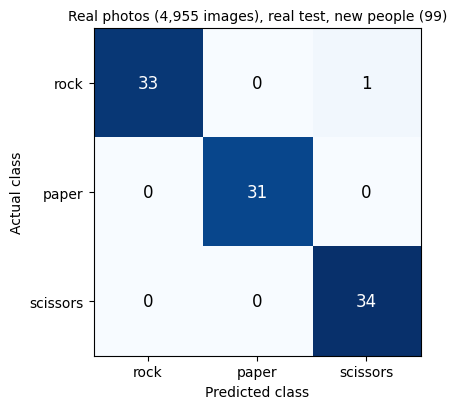

              precision    recall  f1-score   support

        rock      1.000     0.971     0.985        34
       paper      1.000     1.000     1.000        31
    scissors      0.971     1.000     0.986        34

    accuracy                          0.990        99
   macro avg      0.990     0.990     0.990        99
weighted avg      0.990     0.990     0.990        99



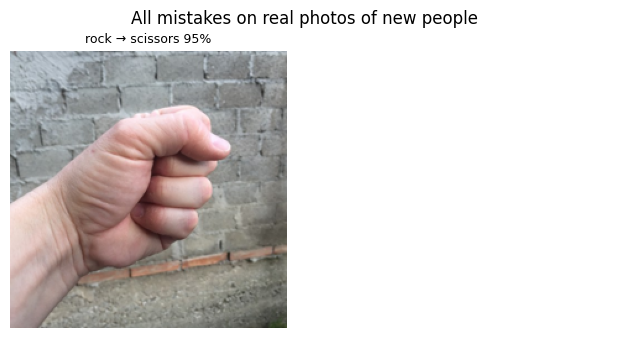

In [ ]:
p = final_model.predict(CORE_SETS[REAL_TEST][0], verbose=0)
y = CORE_SETS[REAL_TEST][1]
plot_confusion(y, p.argmax(1), f'Real photos (4,955 images), {REAL_TEST}')
print(classification_report(y, p.argmax(1), target_names=CLASS_NAMES, digits=3))
wrong = np.where(p.argmax(1) != y)[0]
if len(wrong):
    fig, axes = plt.subplots(1, max(len(wrong), 2), figsize=(3.2 * max(len(wrong), 2), 3.4))
    for ax in np.array(axes).flat: ax.axis('off')
    for ax, i in zip(np.array(axes).flat, wrong):
        ax.imshow(CORE_SETS[REAL_TEST][0][i]); ax.set_title(f"{CLASS_NAMES[y[i]]} → {CLASS_NAMES[p[i].argmax()]} {p[i].max():.0%}", fontsize=9)
    plt.suptitle('All mistakes on real photos of new people'); plt.tight_layout(); plt.show()

**Analysis.** The leakage check removed 4 of the 103 real test photos. On the remaining 99 photos of new people the model scores **99.0%** (98 of 99), against **67.7%** for the background-randomization model without real photos (original run: 97.0% vs 68.9%).

| Held-out set | Without real photos | With real photos |
|---|---:|---:|
| Public test (372) | 73.9% | 100.0% |
| Real validation, other groups of people (276) | 64.5% | 96.7% |
| Real test, new people (99) | 67.7% | 99.0% |
| Green-screen test (150) | 46.7% | 99.3% |

The prediction was correct.

**Real data was the fix that augmentation could not provide.** In my original run my own photos also went from 2 / 6 to 5 / 6.

## 12. Can a smaller training set do as well?

**Question.** Is all that data needed? I train the same recipe on 2,400 images:
* 300 computer-generated images per gesture
* 400 real photos per gesture, taken evenly from every group of people, with exact duplicates removed
* 100 green-screen photos per gesture

**Prediction:** slightly lower on real photos of new people (94–97%), public test still above 97%.

In [ ]:
pick = np.random.default_rng(SEED)
groups = np.array([path.split('/')[-3] for path, _ in giusti_items(['D2', 'D4', 'D5', 'D6', 'D7', 'D8'])])
digests = [md5(a) for a in real_train_x]
first_seen = {}
unique = np.array([first_seen.setdefault(d, i) == i for i, d in enumerate(digests)])
print(f"exact duplicates among the {len(digests)} real training photos: {int((~unique).sum())}")

def spread_over_groups(label, n):
    """Take photos of one gesture from every group of people in turn."""
    pools = [pick.permutation(np.where((real_train_y == label) & (groups == g) & unique)[0]).tolist() for g in sorted(set(groups))]
    chosen = []
    while len(chosen) < n and any(pools):
        for pool in pools:
            if pool and len(chosen) < n:
                chosen.append(pool.pop())
    return chosen

real_idx = np.array(sum((spread_over_groups(c, 400) for c in range(3)), []))
green_idx = np.concatenate([pick.choice(np.where(green_train_y == c)[0], 100, replace=False) for c in range(3)])
small_photo_x = np.concatenate([real_train_x[real_idx], green_train_x[green_idx]])
small_photo_y = np.concatenate([real_train_y[real_idx], green_train_y[green_idx]])

cgi_labels = np.array([int(l) for _, l in tfds.as_numpy(train_raw)])
keep_cgi = np.zeros(len(cgi_labels), dtype=bool)
for c in range(3):
    keep_cgi[pick.choice(np.where(cgi_labels == c)[0], 300, replace=False)] = True
keep_cgi_tf = tf.constant(keep_cgi)
def is_selected(index, img, mask, label): return tf.gather(keep_cgi_tf, index)
def drop_index(index, img, mask, label): return img, mask, label
small_hands = (hands_ds.enumerate().map(lambda index, hand: (index, hand[0], hand[1], hand[2]))
               .filter(is_selected).map(drop_index).cache())
n_small_cgi = int(keep_cgi.sum())
print(f"smaller training set: {n_small_cgi} computer-generated + {len(small_photo_y)} real = {n_small_cgi + len(small_photo_y)}")

def small_mixed(photo_x, photo_y, extra_map=None):
    """The smaller training set as a stream; extra_map is applied to every batch (used in section 15)."""
    cgi = (tf.data.Dataset.zip((small_hands.shuffle(n_small_cgi, seed=SEED).batch(BATCH_SIZE), bg_ds.batch(BATCH_SIZE)))
           .map(lambda hands, bgs: random_background(hands[0], hands[1], hands[2], bgs), num_parallel_calls=tf.data.AUTOTUNE)
           .unbatch().repeat())
    photos = (tf.data.Dataset.from_tensor_slices((photo_x, photo_y)).shuffle(len(photo_y), seed=SEED).repeat()
              .map(lambda x, y: (tf.cast(x, tf.float32), y)))
    total = n_small_cgi + len(photo_y)
    ds = tf.data.Dataset.sample_from_datasets([cgi, photos], weights=[n_small_cgi / total, len(photo_y) / total], seed=SEED).batch(BATCH_SIZE)
    if extra_map is not None:
        ds = ds.map(extra_map, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE), total // BATCH_SIZE

small_ds, small_steps = small_mixed(small_photo_x, small_photo_y)
small_model = train_two_stage(small_ds, small_steps, 'rps_2400')
core_preds = evaluate_sets({'real photos (4,955)': final_model, 'smaller set (2,400)': small_model}, CORE_SETS)
print_paired(core_preds, CORE_SETS, 'smaller set (2,400)', 'real photos (4,955)')

exact duplicates among the 2063 real training photos: 19
smaller training set: 900 computer-generated + 1500 real = 2400
Epoch 1/6
75/75 - 15s - 194ms/step - accuracy: 0.5125 - loss: 1.0298 - val_accuracy: 0.7101 - val_loss: 0.7162
Epoch 2/6
75/75 - 6s - 76ms/step - accuracy: 0.6675 - loss: 0.7741 - val_accuracy: 0.7065 - val_loss: 0.6854
Epoch 3/6
75/75 - 7s - 94ms/step - accuracy: 0.7033 - loss: 0.6832 - val_accuracy: 0.7536 - val_loss: 0.6121
Epoch 4/6
75/75 - 6s - 78ms/step - accuracy: 0.7212 - loss: 0.6376 - val_accuracy: 0.7355 - val_loss: 0.5962
Epoch 5/6
75/75 - 7s - 89ms/step - accuracy: 0.7287 - loss: 0.6335 - val_accuracy: 0.7572 - val_loss: 0.5808
Epoch 6/6
75/75 - 6s - 78ms/step - accuracy: 0.7638 - loss: 0.5910 - val_accuracy: 0.7681 - val_loss: 0.5741
Epoch 1/16
75/75 - 23s - 301ms/step - accuracy: 0.7833 - loss: 0.5375 - val_accuracy: 0.7899 - val_loss: 0.5469
Epoch 2/16
75/75 - 9s - 124ms/step - accuracy: 0.8737 - loss: 0.3176 - val_accuracy: 0.8623 - val_loss: 0.3730


**Analysis.** On the earlier test sets the smaller set is almost as good:
* real photos of new people **98.0% vs 99.0%** (one photo)
* real validation 94.9% vs 96.7% (4 vs 9 pictures only one model gets right, p = 0.27, not significant)
* 100% on the public test for both

Training took 204 s instead of 394 s. Preparing the subset also uncovered 19 exact duplicates among the 2,063 real training photos. The prediction was roughly correct: slightly lower, though 98.0% is above the predicted range.

With less than half of the images the model performs almost the same on these sets. **The pretrained backbone and the variety of the data (several sources, many people) matter more than the number of images.**

## 13. Real-world test: 900 new people in their own rooms (HaGRID)

My real test photos are mostly close-ups of a hand on a table. A much more varied test: **HaGRID** (HAnd Gesture Recognition Image Dataset), photographed by thousands of people with their own phone or webcam in their own rooms. I use the 30k sample at 384 px:
* *fist* = rock, *palm* = paper, *peace* = scissors
* 300 photos per gesture, **one photo per person**
* a square cut around the annotated hand at 1.7 × the hand size

Neither model has seen any of these pictures.

**Prediction:** both models clearly below the earlier real test (below 85%), scissors weakest, the two models within 3 points of each other.

Using Colab cache for faster access to the 'hagrid-sample-30k-384p' dataset.
HaGRID test set: 900 photos from 900 different people


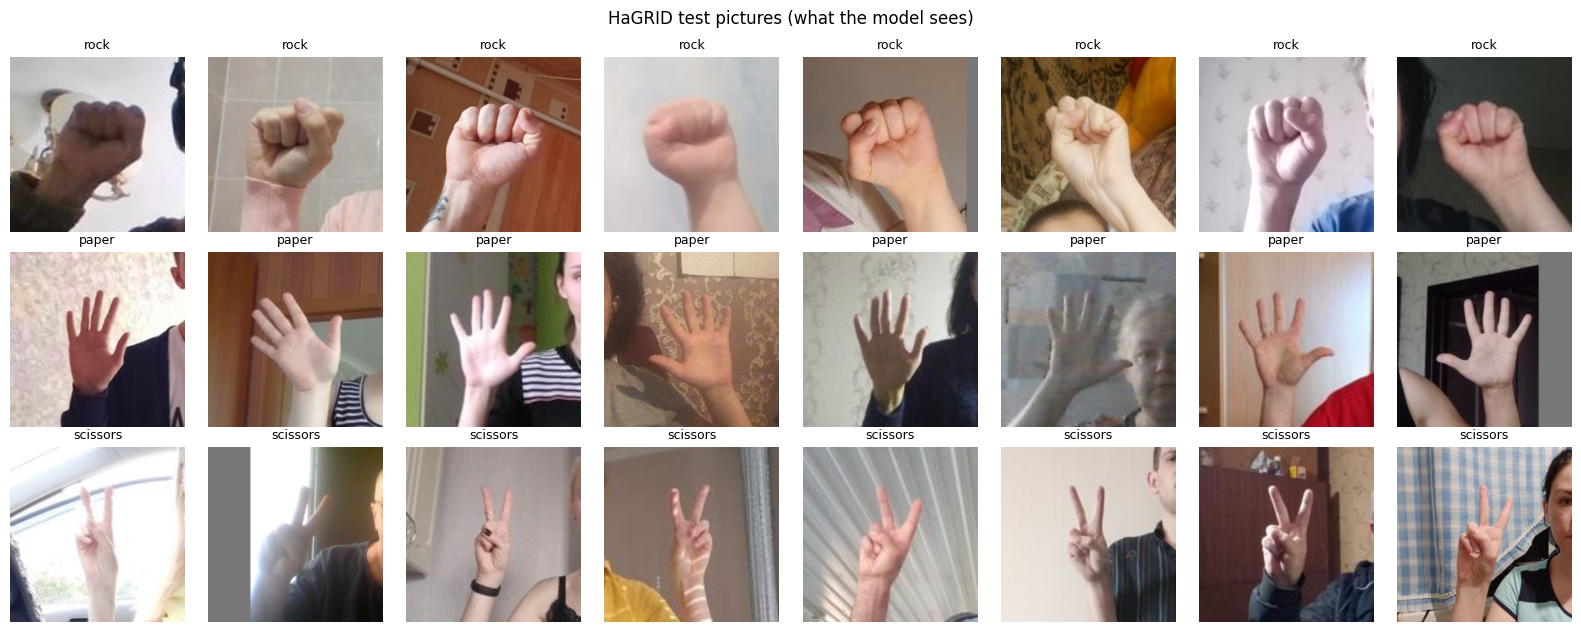

test set                                 real photos (4,955)     smaller set (2,400)
HaGRID, 900 people                                     95.3%                   93.2%

Paired comparison: real photos (4,955) vs smaller set (2,400) (pictures only one of them gets right; sign test)
  HaGRID, 900 people                   only real photos (4,955) right:   33 | only smaller set (2,400) right:   14 | p = 0.008


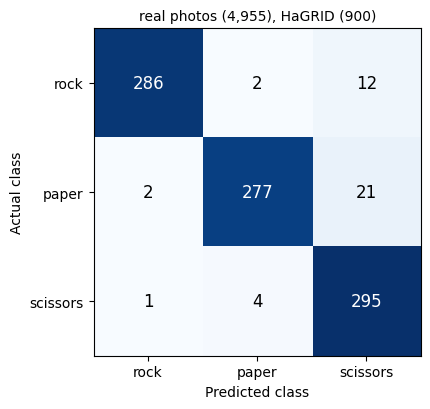

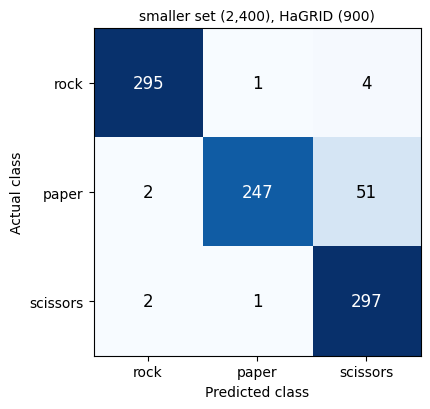

In [ ]:
hagrid_root = os.path.join(kagglehub.dataset_download('innominate817/hagrid-sample-30k-384p'), 'hagrid-sample-30k-384p')
HAGRID_CLASSES = {'fist': 0, 'palm': 1, 'peace': 2}
PER_CLASS, MARGIN, MIN_HAND_PX = 300, 1.7, 64

def square_around(img, box, margin=MARGIN, size=300):
    """Square crop centred on the hand (box = x, y, w, h in pixels); outside the photo is filled grey."""
    x, y, w, h = box
    side = int(round(margin * max(w, h)))
    left, top = int(round(x + w / 2 - side / 2)), int(round(y + h / 2 - side / 2))
    canvas = Image.new('RGB', (side, side), (119, 119, 119))
    canvas.paste(img.crop((max(left, 0), max(top, 0), min(left + side, img.width), min(top + side, img.height))), (max(-left, 0), max(-top, 0)))
    return np.array(canvas.resize((size, size), Image.BILINEAR))

hag_rng = np.random.default_rng(SEED)
hag_x, hag_y = [], []
for gesture, label in HAGRID_CLASSES.items():
    ann = json.load(open(f'{hagrid_root}/ann_train_val/{gesture}.json'))
    folder = f'{hagrid_root}/hagrid_30k/train_val_{gesture}'
    users, taken = set(), 0
    for fname in hag_rng.permutation(sorted(os.listdir(folder))):
        a = ann.get(fname[:-4])
        boxes = [b for b, l in zip(a['bboxes'], a['labels']) if l == gesture] if a else []
        if len(boxes) != 1 or a['user_id'] in users:
            continue
        img = Image.open(f'{folder}/{fname}').convert('RGB')
        bx, by, bw, bh = boxes[0]
        box = (bx * img.width, by * img.height, bw * img.width, bh * img.height)
        if max(box[2], box[3]) < MIN_HAND_PX:
            continue
        users.add(a['user_id']); hag_x.append(square_around(img, box)); hag_y.append(label); taken += 1
        if taken == PER_CLASS:
            break
hag_x, hag_y = np.stack(hag_x), np.array(hag_y)
print(f"HaGRID test set: {len(hag_y)} photos from {len(hag_y)} different people")

fig, axes = plt.subplots(3, 8, figsize=(16, 6.4))
for row in range(3):
    for ax, i in zip(axes[row], hag_rng.choice(np.where(hag_y == row)[0], 8, replace=False)):
        ax.imshow(hag_x[i]); ax.axis('off'); ax.set_title(CLASS_NAMES[row], fontsize=9)
plt.suptitle('HaGRID test pictures (what the model sees)'); plt.tight_layout(); plt.show()

HAGRID = {'HaGRID, 900 people': (hag_x, hag_y)}
hag_preds = evaluate_sets({'real photos (4,955)': final_model, 'smaller set (2,400)': small_model}, HAGRID)
print_paired(hag_preds, HAGRID, 'real photos (4,955)', 'smaller set (2,400)')
for name in ['real photos (4,955)', 'smaller set (2,400)']:
    plot_confusion(hag_y, hag_preds['HaGRID, 900 people', name], f'{name}, HaGRID (900)')

**Analysis.** The 4,955-image model scores **95.3%**, the smaller set **93.2%**. On this more varied test the extra data does help: the larger model is right on 33 pictures where the smaller one is wrong, and the reverse on only 14 (p = 0.008). In my original run the gap was smaller and not significant (95.0% vs 94.1%).

The prediction was wrong, in a good way. When the picture is cut around the hand, both models also work on new people in ordinary rooms. The main remaining mistake is an **open palm read as scissors**.

## 14. Hard cases: hand angles, shadows and colour

I do not know what the hidden set looks like, so I tested the situations where I expected the models to be weakest:

1. **Hard hand angles.** 3,871 labelled photos ([nicokofi/Rock-Paper-Scissors-Hand-Data](https://huggingface.co/datasets/nicokofi/Rock-Paper-Scissors-Hand-Data)) with hands pointing down, seen from below, partly outside the picture or blurred. All are black-and-white, 96 × 96 px.
2. **One change at a time on HaGRID:** smaller (96 px), dim light (35% brightness), colour removed, and a hard shadow across part of the picture (one side darkened to 45% along a random straight edge).

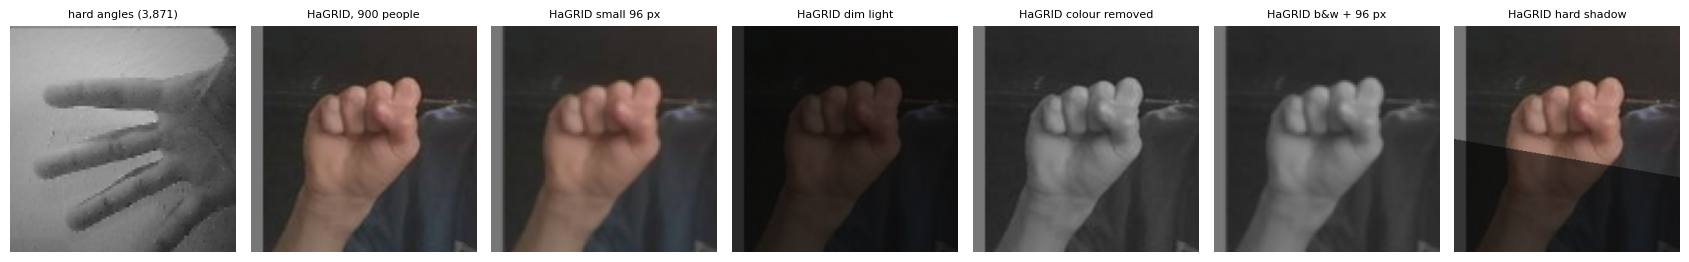

test set                                 real photos (4,955)     smaller set (2,400)
hard angles (3,871)                                    91.2%                   89.2%
HaGRID, 900 people                                     95.3%                   93.2%
HaGRID small 96 px                                     93.3%                   92.3%
HaGRID dim light                                       91.2%                   92.0%
HaGRID colour removed                                  91.6%                   88.2%
HaGRID b&w + 96 px                                     89.9%                   84.1%
HaGRID hard shadow                                     78.3%                   76.7%
real photos (4,955): paper read correctly with a shadow 54% (without: 92%)
smaller set (2,400): paper read correctly with a shadow 45% (without: 82%)


In [ ]:
from huggingface_hub import hf_hub_download
zipfile.ZipFile(hf_hub_download('nicokofi/Rock-Paper-Scissors-Hand-Data', 'RPS Hand Data.zip', repo_type='dataset')).extractall('/content/nicokofi')
nk_paths = sorted(f for f in glob.glob('/content/nicokofi/**/*', recursive=True) if f.lower().endswith(('.jpg', '.jpeg', '.png')))
nk_x = np.stack([np.array(Image.open(f).convert('RGB')) for f in nk_paths])
nk_y = np.array([CLASS_NAMES.index(f.split('/')[-2].lower()) for f in nk_paths])

light_rng = np.random.default_rng(7)
def black_and_white(x): return np.stack([np.array(Image.fromarray(a).convert('L').convert('RGB')) for a in x])
def small96(x):         return np.stack([np.array(Image.fromarray(a).resize((96, 96), Image.BILINEAR)) for a in x])
def dim(x, k=0.35):     return (x * k).astype(np.uint8)
def hard_shadow(x, strength=0.45):
    yy, xx = np.mgrid[0:x.shape[1], 0:x.shape[2]]
    out = []
    for a in x:
        angle = light_rng.uniform(0, np.pi); px, py = light_rng.uniform(0.3, 0.7, 2) * x.shape[1]
        dark = (np.cos(angle) * (xx - px) + np.sin(angle) * (yy - py)) > 0
        out.append((a * np.where(dark, strength, 1.0)[..., None]).astype(np.uint8))
    return np.stack(out)

HARD_SETS = {
    'hard angles (3,871)':   (nk_x, nk_y),
    'HaGRID, 900 people':    (hag_x, hag_y),
    'HaGRID small 96 px':    (small96(hag_x), hag_y),
    'HaGRID dim light':      (dim(hag_x), hag_y),
    'HaGRID colour removed': (black_and_white(hag_x), hag_y),
    'HaGRID b&w + 96 px':    (small96(black_and_white(hag_x)), hag_y),
    'HaGRID hard shadow':    (hard_shadow(hag_x), hag_y),
}
fig, axes = plt.subplots(1, 7, figsize=(17, 2.9))
for ax, (name, (x, _)) in zip(axes, HARD_SETS.items()):
    ax.imshow(x[5]); ax.axis('off'); ax.set_title(name, fontsize=8)
plt.tight_layout(); plt.show()

hard_preds = evaluate_sets({'real photos (4,955)': final_model, 'smaller set (2,400)': small_model}, HARD_SETS)
for name in ['real photos (4,955)', 'smaller set (2,400)']:
    shadow_pred = hard_preds['HaGRID hard shadow', name]
    print(f"{name}: paper read correctly with a shadow {(shadow_pred[hag_y == 1] == 1).mean():.0%} "
          f"(without: {(hard_preds['HaGRID, 900 people', name][hag_y == 1] == 1).mean():.0%})")

**Analysis.**

| Change (HaGRID unless stated) | Real photos (4,955) | Smaller set (2,400) |
|---|---:|---:|
| None | 95.3% | 93.2% |
| Small, 96 px | 93.3% | 92.3% |
| Dim light | 91.2% | 92.0% |
| Colour removed | 91.6% | 88.2% |
| Black-and-white + 96 px | 89.9% | 84.1% |
| Hard angles (3,871, black-and-white 96 px) | 91.2% | 89.2% |
| **Hard shadow** | **78.3%** | **76.7%** |

* **A shadow across the hand is by far the largest weakness:** 15–17 points. Paper collapses: it is read correctly only 54% / 45% of the time, against 92% / 82% without a shadow.
* **Removing colour costs 4–5 points**, so the models partly rely on skin colour.
* **Small pictures cost 1–2 points, dim light 1–4.**
* **Hard angles cost little beyond the photo format:** HaGRID in the same black-and-white, 96 px format scores about the same.

## 15. The fix: training with random shadows and black-and-white pictures

**Change.** Retrain the smaller-set model on exactly the same 2,400 images with the same settings and seed. During training only:
* 40% of the pictures get a random shadow (random direction, darkness 30–75%, soft or hard edge)
* 20% are made black-and-white

This happens in the data pipeline, not in the model, so the saved model is unchanged in size and needs no custom code.

**Prediction:** at least +5 points with a hard shadow and with colour removed, at least +1 point on hard angles, no loss (within 1 point) on every other held-out set.

**Caution:** the artificial shadow test uses the same kind of shadow as the training, so a gain there is expected and is not independent evidence.

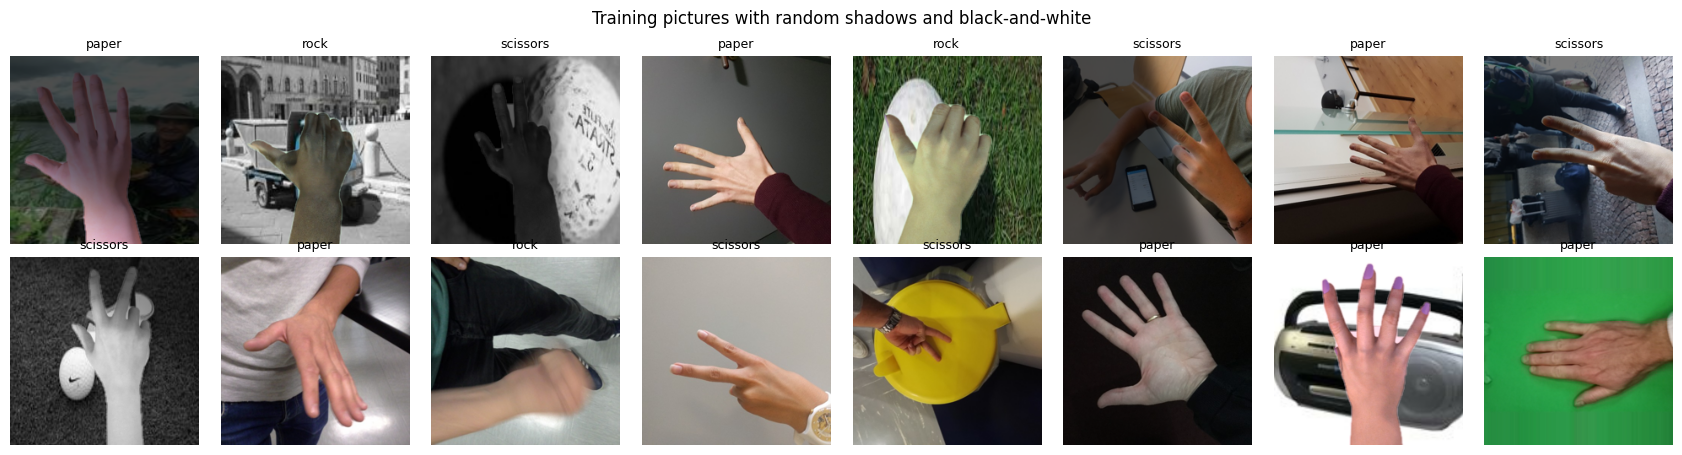

Epoch 1/6
75/75 - 18s - 246ms/step - accuracy: 0.5071 - loss: 1.0485 - val_accuracy: 0.6413 - val_loss: 0.7758
Epoch 2/6
75/75 - 11s - 144ms/step - accuracy: 0.6550 - loss: 0.7939 - val_accuracy: 0.7464 - val_loss: 0.6550
Epoch 3/6
75/75 - 11s - 147ms/step - accuracy: 0.7013 - loss: 0.6862 - val_accuracy: 0.7391 - val_loss: 0.6177
Epoch 4/6
75/75 - 11s - 147ms/step - accuracy: 0.7063 - loss: 0.6872 - val_accuracy: 0.7609 - val_loss: 0.6053
Epoch 5/6
75/75 - 11s - 146ms/step - accuracy: 0.7346 - loss: 0.6514 - val_accuracy: 0.7319 - val_loss: 0.5925
Epoch 6/6
75/75 - 10s - 131ms/step - accuracy: 0.7379 - loss: 0.6268 - val_accuracy: 0.7500 - val_loss: 0.5913
Epoch 1/16
75/75 - 26s - 353ms/step - accuracy: 0.7717 - loss: 0.5570 - val_accuracy: 0.7862 - val_loss: 0.5104
Epoch 2/16
75/75 - 12s - 159ms/step - accuracy: 0.8608 - loss: 0.3611 - val_accuracy: 0.8406 - val_loss: 0.4579
Epoch 3/16
75/75 - 13s - 172ms/step - accuracy: 0.9079 - loss: 0.2725 - val_accuracy: 0.8659 - val_loss: 0.413

In [ ]:
SHADOW_SHARE, BW_SHARE = 0.4, 0.2
def shadow_and_bw(images, labels):
    n, h, w = tf.shape(images)[0], tf.shape(images)[1], tf.shape(images)[2]
    yy, xx = tf.meshgrid(tf.range(h, dtype=tf.float32), tf.range(w, dtype=tf.float32), indexing='ij')
    angle = tf.random.uniform([n, 1, 1], 0.0, 2 * np.pi)
    cx = tf.random.uniform([n, 1, 1], 0.25, 0.75) * tf.cast(w, tf.float32)
    cy = tf.random.uniform([n, 1, 1], 0.25, 0.75) * tf.cast(h, tf.float32)
    distance = tf.cos(angle) * (xx - cx) + tf.sin(angle) * (yy - cy)
    softness = tf.random.uniform([n, 1, 1], 1.0, 30.0)               # 1 px = hard edge, 30 px = soft edge
    darkness = tf.random.uniform([n, 1, 1], 0.30, 0.75)              # brightness kept on the dark side
    shade = 1.0 - (1.0 - darkness) * tf.sigmoid(distance / softness)
    use = tf.cast(tf.random.uniform([n, 1, 1]) < SHADOW_SHARE, tf.float32)
    images = images * (1.0 - use + use * shade)[..., tf.newaxis]
    grey = tf.image.grayscale_to_rgb(tf.image.rgb_to_grayscale(images))
    return tf.where(tf.random.uniform([n, 1, 1, 1]) < BW_SHARE, grey, images), labels

shadow_ds, shadow_steps = small_mixed(small_photo_x, small_photo_y, extra_map=shadow_and_bw)
px, py = next(iter(shadow_ds))
fig, axes = plt.subplots(2, 8, figsize=(17, 4.6))
for ax, img, lab in zip(axes.flat, px, py):
    ax.imshow(img.numpy().clip(0, 255).astype('uint8')); ax.set_title(CLASS_NAMES[int(lab)], fontsize=9); ax.axis('off')
plt.suptitle('Training pictures with random shadows and black-and-white'); plt.tight_layout(); plt.show()

shadow_model = train_two_stage(shadow_ds, shadow_steps, 'rps_2400_shadows')
ALL_SETS = {**CORE_SETS, **HARD_SETS}
CANDIDATES = {'real photos (4,955)': final_model, 'smaller set (2,400)': small_model, 'small + shadows': shadow_model}
all_preds = evaluate_sets(CANDIDATES, ALL_SETS)
print_paired(all_preds, ALL_SETS, 'small + shadows', 'smaller set (2,400)')

**Analysis.** Compared with the smaller-set model trained on the same images with the same seed and settings:

| Held-out set | Smaller set | **+ shadow training** | Only one model right (shadow vs smaller) |
|---|---:|---:|---|
| Hard angles (3,871) | 89.2% | **92.9%** | 169 vs 25 (p < 0.001) |
| HaGRID, 900 people | 93.2% | **94.8%** | 22 vs 8 (p = 0.016) |
| HaGRID colour removed | 88.2% | **90.9%** | 35 vs 11 (p = 0.001) |
| HaGRID black-and-white + 96 px | 84.1% | **89.0%** | 62 vs 18 (p < 0.001) |
| HaGRID hard shadow* | 76.7% | **79.3%** | 40 vs 16 (p = 0.002) |
| HaGRID dim light | 92.0% | 93.3% | 30 vs 18 (p = 0.11) |
| Real validation (276) | **94.9%** | 92.8% | 1 vs 7 (p = 0.07) |
| Real test, new people (99) | **98.0%** | 94.9% | 0 vs 3 (p = 0.25) |
| Public test (372) | 100.0% | 99.7% | 0 vs 1 |

\*Same kind of shadow as in training, so not independent evidence.

**Prediction check.**
* *At least +1 point on hard angles:* correct (+3.7).
* *At least +5 points with a shadow and without colour:* wrong; the gains were +2.6 and +2.7.
* *No loss elsewhere:* **wrong in this run.** It loses 3 of the 99 real test photos and is slightly lower on real validation, though neither difference is statistically significant. In my original run the real test was unchanged (96.0% vs 96.0%), and the gains on HaGRID were similar.

**What this shows.** Training with shadows and black-and-white pictures clearly makes the model more robust to hard angles, missing colour and shadows. The price is a small, uncertain loss on close-up photos like the Giusti dataset. Against the 4,955-image model the picture is mixed:
* The shadow model is better on hard angles, dim light and shadows.
* The 4,955-image model is better on the real photos of new people (99.0% vs 94.9%) and on normal HaGRID photos (95.3% vs 94.8%).

**Doubling the real data helps normal photos; shadow training helps hard lighting.** A next step would be to combine the two.

## 16. Independent check: my own photos

Every public test set had by now been used to choose between models. The independent check was new photos of my own hands, taken **after** all models were trained and chosen. Most paper and scissors photos show the fingers pointing towards the camera, the pose I expected to be hardest.

**Results in my original run** (photos not included):

| Photos | Real photos (4,955) | Smaller (2,400) | Small + shadows |
|---|---:|---:|---:|
| Batch 1: 15 photos, one room, whole photo | 9 / 15 | 10 / 15 | **12 / 15** |
| Batch 2: 80 photos, two rooms, people in the background | 48 / 80 (60%) | 51 / 80 (64%) | **53 / 80 (66%)** |

* **Rock was always correct** (5 / 5 and 17 / 17 for every model).
* **Scissors pointing at the camera** is often read as rock: from the front, two fingers look short and close together.
* **Open hands seen at an angle** are often read as scissors.
* **The shadow-trained model was best in both batches,** in line with every larger test. On these photos all models are far below their public test scores, which shows **how much a test set's conditions matter.**

In [ ]:
if OWN_TEST:
    for mode in ['centre square', 'whole photo']:
        print(f"\n=== {mode} ===")
        own_preds = evaluate_sets(CANDIDATES, own_arrays(mode))
else:
    print("No own photos uploaded: see the recorded results above.")

No own photos uploaded: see the recorded results above.


## 17. Does it help to train on my own photos?

**Idea.** The models are weak on hands photographed from the front, and my 80 batch-2 photos show exactly that. So I retrain the shadow-trained model with these 80 photos added, each used 4 times per epoch (about 12% of the training pictures). The 15 batch-1 photos stay test-only.

**Control.** In my original run, Colab's TensorFlow version had changed since the shadow-trained model was trained, which changes the random numbers. I therefore also repeated the run **without** my photos on the same software. Inside a single run of this notebook, the shadow-trained model of section 15 is that control.

**Prediction:** better on my own test photos, no loss elsewhere.

**Result in my original run:**

| Test set | Control (no own photos) | With my 80 photos |
|---|---:|---:|
| Real photos, new people (99) | 96.0% | 96.0% |
| Real validation (276) | 93.1% | 90.9% |
| Hard angles (3,871) | 94.3% | **91.7%** (26 vs 126 pictures, p < 0.001) |
| HaGRID (900) | 97.2% | **95.4%** (p = 0.002) |
| HaGRID hard shadow | 83.9% | **79.2%** (p < 0.001) |

**The prediction was wrong. Adding my photos made the model clearly worse on everyone else's photos,** and it learned only 80% of the 80 training photos itself. Possible reasons, not tested:
* the photos come from one or two people in two rooms, so the model may learn the rooms instead of the hands
* padding portrait photos to a square adds stretched border stripes that appear in no other training data
* some open hands seen at an angle are genuinely ambiguous

**First attempt rejected.** A second lesson: the control and the original shadow-trained model use the same recipe, yet differ by up to 1.3 points. **One point between two models trained once is within run-to-run noise.**

**Second attempt.** Later I retrained all three candidates with these photos (77 after removing 3 exact copies, compared with the saved original models). This time the smaller-set models improved:

| Test set | Small + shadows | With my photos |
|---|---:|---:|
| Real photos, new people (99) | 96.0% | 99.0% |
| Hard angles (3,871) | 93.1% | 94.8% (105 vs 37 pictures, p < 0.001) |
| HaGRID (900) | 95.9% | 97.8% (p = 0.002) |
| HaGRID hard shadow | 82.9% | 86.0% (p = 0.001) |

The 4,955-image model with my photos was mixed: better on real validation (93.5% → 97.5%), worse on hard angles (91.7% → 89.4%). This attempt had **no same-session control**: the originals were trained days earlier on an older TensorFlow version, so part of the gain may be run-to-run variation. The two attempts disagree, so the effect of my photos is unresolved. I use this model as the final one because it was the strongest on the held-out sets, with that caution stated.

In [ ]:
if 'train' in OWN_SETS:
    own_imgs, own_labels = OWN_SETS['train']
    own_train_x = np.stack([to_square(im, 'whole photo', 224) for im in own_imgs])
    own_photo_x = np.concatenate([small_photo_x] + [own_train_x] * 4)
    own_photo_y = np.concatenate([small_photo_y] + [own_labels] * 4)
    own_ds, own_steps = small_mixed(own_photo_x, own_photo_y, extra_map=shadow_and_bw)
    own_model = train_two_stage(own_ds, own_steps, 'rps_2400_shadows_own')
    print(f"own training photos learned: {(own_model.predict(own_train_x, verbose=0).argmax(1) == own_labels).mean():.0%}")
    test_sets = {**ALL_SETS, **(own_arrays('whole photo') if OWN_TEST else {})}
    own_preds = evaluate_sets({'small + shadows': shadow_model, 'shadows + own photos': own_model}, test_sets)
    print_paired(own_preds, test_sets, 'shadows + own photos', 'small + shadows')
else:
    print("No 'train' photo set uploaded: see the recorded result above.")

No 'train' photo set uploaded: see the recorded result above.


## 18. The instructor's test photos

My instructor gave me a test set of real photos from the students in the class: data I did not collect and never trained on. I tested all six saved models on it with **no training or tuning**. Each photo was used whole and resized to 300 × 300. After removing 6 exact duplicate files, **262 photos** remained: 87 rock, 87 paper and 88 scissors. The photos are private and not included here, so these are the recorded results.

| Model | Correct | Accuracy | Rock (87) | Paper (87) | Scissors (88) |
|---|---:|---:|---:|---:|---:|
| Real photos (4,955 images) | 235 / 262 | 89.7% | 84 | 79 | 72 |
| Smaller set (2,400 images) | 227 / 262 | 86.6% | 78 | 71 | 78 |
| Small + shadows | 233 / 262 | 88.9% | 77 | 76 | 80 |
| Real photos + own photos | 240 / 262 | 91.6% | 81 | 77 | 82 |
| Smaller set + own photos | 239 / 262 | 91.2% | 77 | 77 | 85 |
| **Small + shadows + own photos** | **242 / 262** | **92.4%** | 82 | 76 | 84 |

**Paired comparison (photos only one of the two models gets right).**

| Comparison | First model only | Second model only | p |
|---|---:|---:|---:|
| Real photos (4,955) vs small + shadows | 12 | 10 | 0.83 |
| Real photos (4,955) vs real photos + own photos | 8 | 13 | 0.38 |
| Smaller set vs smaller set + own photos | 3 | 15 | 0.008 |
| Small + shadows vs small + shadows + own photos | 1 | 10 | 0.012 |
| Real photos (4,955) vs small + shadows + own photos | 7 | 14 | 0.19 |

**What this shows.**
* All six models scored between 86.6% and 92.4% on photos from people and cameras they had never been tested on before.
* Among the three original candidates, the 4,955-image model and the shadow-trained model are level (12 vs 10).
* Scissors separates the models most. The 4,955-image model gets 72 of 88, and every model trained with my own photos reaches at least 82.
* My own photos clearly helped both smaller-set models (3 vs 15 and 1 vs 10). The gain on the 4,955-image model is not significant.
* Small + shadows + own photos scored highest, but its lead over the 4,955-image model is not significant (7 vs 14, p = 0.19).

**Limits.**
* With 262 photos the margin of error of a single score is about ±3.6 points.
* The models with own photos were trained in a later session on a newer TensorFlow version, with no same-session control (section 17).
* At least one person in my own training photos is also in this test set, which may favour those models. A checksum comparison found no exact copies of my training photos in this set, though a resaved copy would not be detected.
* No prediction was written down before this test.
* All six models were tested with the same image preparation on a laptop CPU, and the five scores first measured in Colab came out identical.

## 19. Deployment check: will the saved model work for someone else?

Before saving a model I checked how another person's evaluation script might call it. The final model was trained on my private photos, so this public notebook rebuilds and checks **small + shadows**, which has the same architecture and input handling.

* **Input format.** The model resizes and scales pixels itself, so it expects raw pixel values 0–255 at any image size. If a script divides by 255 first, the model scales twice, sees an almost black picture and guesses (33%).
* **The guard.** I put a small step in front of the model: if all pixels of an image are 1 or below, they are multiplied by 255. Raw images pass through unchanged. It uses only built-in Keras operations, so the saved file loads without any of my code.

The cell saves that model, then checks it the way a stranger would: in a **brand-new Python process**, with raw and with divided-by-255 images.

In [ ]:
from keras import ops

def add_input_guard(model, name='rps_final'):
    image = tf.keras.Input(shape=(None, None, 3), name='image')
    peak = ops.max(image, axis=[1, 2, 3], keepdims=True)
    return tf.keras.Model(image, model(image * ops.where(peak <= 1.0, 255.0, 1.0)), name=name)

json.dump(RESULTS, open('results.json', 'w'), indent=1)   # all results so far, kept on disk for section 20
deploy_model = add_input_guard(shadow_model)
deploy_model.save('rps_final_model.keras')
np.save('public_test_x.npy', cgi_test_x); np.save('public_test_y.npy', cgi_test_y)
print(f"saved rps_final_model.keras ({os.path.getsize('rps_final_model.keras') / 1e6:.1f} MB)")
print(f"without the guard, images divided by 255: {(shadow_model.predict(cgi_test_x / 255.0, verbose=0).argmax(1) == cgi_test_y).mean():.1%}")

# The check runs in a second Python process. Free the large test sets first and keep that process on the CPU,
# otherwise two TensorFlow processes can run out of memory together (this happened in my first full run).
import gc
for name in ['HARD_SETS', 'ALL_SETS', 'hag_x', 'nk_x', 'real_train_x', 'photo_train_x', 'green_train_x']:
    globals().pop(name, None)
gc.collect()
check = ("import numpy as np, tensorflow as tf; m = tf.keras.models.load_model('rps_final_model.keras'); "
         "x, y = np.load('public_test_x.npy'), np.load('public_test_y.npy'); "
         "acc = lambda a: (m.predict(a, batch_size=64, verbose=0).argmax(1) == y).mean(); "
         "print(f'fresh process: loads without our code | raw 0-255: {acc(x):.1%} | divided by 255: {acc(x / 255.0):.1%} | 150 px: {acc(tf.image.resize(x, (150, 150)).numpy()):.1%}')")
r = subprocess.run([sys.executable, '-c', check], capture_output=True, text=True, env={**os.environ, 'CUDA_VISIBLE_DEVICES': '-1'})
print((r.stdout.strip().splitlines() or ['FAILED: ' + r.stderr[-1500:]])[-1])
same = np.allclose(shadow_model.predict(cgi_test_x, verbose=0), tf.keras.models.load_model('rps_final_model.keras').predict(cgi_test_x, verbose=0), atol=1e-6)
print("guard changes no answer on raw images:", same)

saved rps_final_model.keras (24.6 MB)
without the guard, images divided by 255: 33.3%
fresh process: loads without our code | raw 0-255: 99.7% | divided by 255: 99.7% | 150 px: 100.0%
guard changes no answer on raw images: True


## 20. Final results and lessons

model                         public test (372  real test, new p  HaGRID, 900 peop  hard angles (3,8  HaGRID dim light  HaGRID colour re  HaGRID hard shad
baseline CNN                             80.9%                 —                 —                 —                 —                 —                 —
CNN + augmentation                       94.6%                 —                 —                 —                 —                 —                 —
MobileNetV2 fine-tuned                   82.0%                 —                 —                 —                 —                 —                 —
background randomization                 73.9%             67.7%                 —                 —                 —                 —                 —
real photos (4,955)                     100.0%             99.0%             95.3%             91.2%             91.2%             91.6%             78.3%
smaller set (2,400)                     100.0%             98.0%      

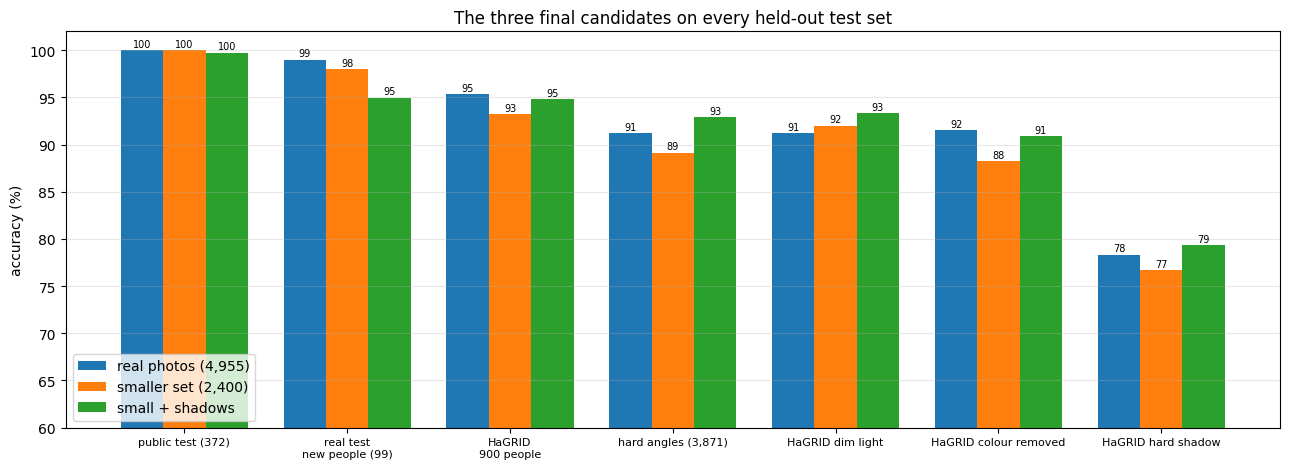

In [ ]:
import json, numpy as np, matplotlib.pyplot as plt
if 'RESULTS' not in globals():                               # e.g. after a runtime restart: use the saved results
    RESULTS = json.load(open('results.json'))
REAL_TEST = next(s for s in RESULTS['small + shadows'] if s.startswith('real test'))
overview_models = ['baseline CNN', 'CNN + augmentation', 'MobileNetV2 fine-tuned', 'background randomization',
                   'real photos (4,955)', 'smaller set (2,400)', 'small + shadows']
overview_sets = ['public test (372)', REAL_TEST, 'HaGRID, 900 people', 'hard angles (3,871)', 'HaGRID dim light', 'HaGRID colour removed', 'HaGRID hard shadow']
print(f"{'model':<28}" + ''.join(f'{s[:16]:>18}' for s in overview_sets))
for m in overview_models:
    print(f'{m:<28}' + ''.join(f"{RESULTS.get(m, {}).get(s, float('nan')):>18.1%}" if s in RESULTS.get(m, {}) else f"{'—':>18}" for s in overview_sets))

fig, ax = plt.subplots(figsize=(13, 4.8))
cands = ['real photos (4,955)', 'smaller set (2,400)', 'small + shadows']
width = 0.26
for k, m in enumerate(cands):
    vals = [RESULTS[m][s] * 100 for s in overview_sets]
    bars = ax.bar(np.arange(len(overview_sets)) + (k - 1) * width, vals, width, label=m)
    ax.bar_label(bars, fmt='%.0f', fontsize=7, padding=1)
ax.set_xticks(range(len(overview_sets))); ax.set_xticklabels([s.replace(', ', '\n') for s in overview_sets], fontsize=8)
ax.set_ylim(60, 102); ax.set_ylabel('accuracy (%)'); ax.legend(loc='lower left'); ax.grid(axis='y', alpha=0.3)
ax.set_title('The three final candidates on every held-out test set')
plt.tight_layout(); plt.show()

### Final model: small + shadows + own photos

| | |
|---|---|
| Architecture | MobileNetV2 (ImageNet) → global average pooling → dropout 0.2 → softmax (3); 2,261,827 parameters |
| Inside the model | resize to 224 × 224, augmentation (flips, any rotation, zoom ±30%, shift ±15%, brightness, contrast), scaling to [−1, 1]; input guard in front |
| Training data | 2,400 images: 900 computer-generated with random backgrounds, 1,200 real (many people), 300 green-screen; plus 77 own photos used 4 times per epoch; random shadows (40%) and black-and-white (20%) during training |
| Training | 6 epochs frozen (Adam 0.001) + up to 16 fine-tuning epochs from layer 100 (Adam 0.00005), weights with the lowest real-validation loss; batch 32, seed 42; 326 s on a T4 |
| Input / output | RGB images of any size, pixel values 0–255 (0–1 also accepted); probabilities for rock, paper, scissors |

**Why this model.** It is the strongest model on the held-out sets that resemble what the hidden set may contain: real photos of new people, hard angles, varied rooms, poor light, missing colour and shadows. Each ingredient came from an experiment: real photos fixed the failure on real hands, shadow training addressed the largest measured weakness, and my own photos added hands seen from the front. It uses under half of the data of the 4,955-image model. I chose it on these sets, not on the instructor's test photos.

**Results of the final model (saved model file)**

| Held-out set | Accuracy |
|---|---:|
| Public test (372) | 100.0% |
| Real validation, other groups of people (276) | 94.6% |
| Real test, new people (99) | 99.0% |
| Green-screen test (150) | 100.0% |
| HaGRID, 900 people in their own rooms | 97.8% |
| Hard hand angles (3,871) | 94.8% |
| HaGRID small 96 px / dim light / colour removed | 96.4% / 95.1% / 94.0% |
| HaGRID black-and-white + 96 px / hard shadow | 91.2% / 86.0% |
| Instructor's test photos (262) | 92.4% |

### Limitations

* Every model was trained once per run. Between my two runs the same code moved by one to several points (17 points in one case), and the ranking of the two best models on some test sets changed.
* The public test set was looked at after many experiments, so its 100% is optimistic. HaGRID and the hard-angle set were used to choose between models and are no longer untouched.
* **Fingers pointing straight at the camera** (scissors, and some open hands) are still often read as rock. On my own photos of that pose the best model reached only about two thirds.
* The real training photos come from one university dataset and one green-screen set: few backgrounds compared with the real world.
* The final model was trained on private photos, so this notebook can rebuild it only if those photos are uploaded. Without them it rebuilds small + shadows.
* The final model had no same-session control, and an earlier attempt to add my photos made the model worse.

### Lessons learned

1. **A test set that looks like the training set measures memory, not generalization.** 100% validation with 81–83% on the public test came from the same flaw, and a model with 90% on the public test still recognised only 2 / 6 real photos.
2. **Check reality early** with a handful of real examples; it changed the direction of the whole project.
3. **Data beats architecture tricks.** Real photos of many people (about +30 points on real photos of new people) did what background randomization and zoom could not.
4. **Diagnose by changing one thing at a time.** It found the hand-size problem and the shadow problem. The targeted shadow fix worked on its target, and paired tests showed its small cost elsewhere honestly.
5. **Write the prediction down first, and keep the failures.** Many predictions here were wrong, and those were the most informative results.
6. **Use paired comparisons and control runs.** One point between two models is noise; consistent wins on the same pictures are not.
7. **Repeat surprising results under the same conditions.** My own photos made the model worse in one attempt and better in another. Without a same-session control I cannot say which is true.
8. **Think about the user of the model.** A model that silently drops to 33% when someone else scales the pixels is not finished.

### Next steps

* Real training photos of hands seen **from the front**, from many different people and places.
* A hand detector that crops the hand before classification. In a webcam prototype this mattered more than the classifier.
* Combine the two strengths: all 4,955 images plus shadow training.
* Several training runs per model, with averaged results.
* Retrain with and without my own photos in one session, to settle what those photos really add.

## 21. Project log: the whole story in one place

The sections above show each experiment in detail. This section lists, from first to last, what I did, what went wrong, how I dealt with it, and how the data changed.

**Two sets of numbers.** Sections 3–15 show the outputs of this notebook's rerun, with the original run noted where it differed. Sections 16–18 and the final model use the saved model files from the original project, because they depend on private photos.

### Timeline

| # | What I did | What I found | What came next |
|---:|---|---|---|
| 1 | Explored the dataset | 2,520 + 372 images, balanced, all computer-generated on white | Built a baseline |
| 2 | Baseline CNN | 100% validation, 81–83% public test | Looked for a better design |
| 3 | Global average pooling | Public test fell to 47–51%; the model underfits | Rejected |
| 4 | Data augmentation | Public test rose to 90–95% | Kept |
| 5 | Transfer learning (MobileNetV2) | 87% frozen, 82% fine-tuned; no gain on this test set | Tested on real photos |
| 6 | My own 6 photos | 1–2 of 6: the models fail on real hands | Changed the direction of the project |
| 7 | Background randomization | Own photos still 2 of 6 | Diagnosed one property at a time |
| 8 | Strong zoom | Only 1 more own photo; unstable results | Stopped augmenting computer-generated images |
| 9 | Added real photographs | Real photos of new people 68% → 97–99% | Main breakthrough |
| 10 | Smaller training set (2,400) | Nearly the same on earlier tests | Kept as a candidate |
| 11 | Browser game (side project) | Many live rounds misjudged | Looked for harder, more realistic tests |
| 12 | HaGRID, 900 people | 93–95% when cut around the hand | Models work on new people |
| 13 | Input format check | Dividing pixels by 255 drops accuracy to 33% | Added an input guard |
| 14 | Hard angles and lighting tests | A shadow costs about 15 points | Trained with shadows |
| 15 | Shadow and black-and-white training | Clearly better on hard cases | New candidate |
| 16 | Own photos, 15 and then 80 | Best model 12 of 15, then 66% of 80 | Tried training on them |
| 17 | Trained on my photos, first attempt | Worse on other people's photos | Rejected, with a control run |
| 18 | Trained all three models on my photos | Better on most tests | Became the final model, with a caution |
| 19 | Instructor's test photos (262) | 87–92% across six models | Recorded with no tuning |

### Difficulties and how I overcame them

| Difficulty | Cause | What I did |
|---|---|---|
| `tensorflow_datasets` would not import | Colab's `tensorflow-metadata` needed a newer protobuf | Pinned an older `tensorflow-metadata`. Downgrading protobuf, my first idea, was wrong and undone |
| 100% validation but much lower test score | Validation came from the same computer-generated images | Stopped trusting validation alone and tested on data from other sources |
| Models answered "rock" on real photos | Training images were all computer-generated, with small hands | Diagnosed one property at a time, then added real photos |
| Background compositing took 82 s per epoch | Hand outlines were recomputed every time | Computed each outline once and cached it: 9 s per epoch |
| Duplicate photos across datasets | The real-photo dataset repeats files across folders | Compared checksums: removed 4 of 103 test photos and 19 training duplicates, then 3 copies in my own photos and 6 in the instructor's set |
| "Too many sessions" in Colab | The free tier allows one GPU session | Closed idle sessions |
| Colab deleted my files when it disconnected | Uploaded and trained files live only on a temporary machine | Downloaded every model straight after training and kept all six in one folder |
| Local photos could not be sent to Colab automatically | Browser security rules block it | Built upload prompts into the notebook cells, one round per gesture, which also gives each photo its label |
| Same code gave different results | Random numbers, GPU behaviour and a TensorFlow update | Used control runs and paired sign tests instead of single scores |
| Shadows cost about 15 points | Training data had few strong shadows | Added random shadows and black-and-white pictures during training only |
| Scaled pixels gave 33% | The model scales pixels itself, so inputs were scaled twice | Added an input guard using only built-in Keras operations |
| Colab crashed at the deployment check | A second TensorFlow process ran out of memory | Saved results to disk, freed large arrays and ran the check on the CPU |
| iPhone `.heic` photos could not be read | Pillow does not read that format by itself | Added `pillow-heif` |
| A `.keras` model cannot run in a browser | Browsers need another format | Exported to ONNX and checked that the answers matched on 372 images |
| Webcam play was much worse than photo tests | Live pictures are not cut around the hand, and the hand moves | Added MediaPipe hand cropping and zoom averaging |
| The sixth instructor-test score was missing | The saved output ended early | Re-ran all six models on a laptop. The five known scores came out identical, which confirmed the test |
| Adding my photos gave opposite results in two attempts | No same-session control in the second attempt | Recorded both results and marked the effect as unresolved |

### How the training data changed

| Version | Computer-generated | Real photos | Green-screen | Own photos | Total | Changes during training only | Used by |
|---:|---:|---:|---:|---:|---:|---|---|
| 1 | 2,142 | 0 | 0 | 0 | 2,142 | None | Baseline, global average pooling |
| 2 | 2,142 | 0 | 0 | 0 | 2,142 | Flip, rotation, zoom, shift, brightness, contrast | CNN + augmentation, MobileNetV2 |
| 3 | 2,142 | 0 | 0 | 0 | 2,142 | Above, plus random backgrounds and stronger geometry | Background randomization |
| 4 | 2,142 | 0 | 0 | 0 | 2,142 | Above, plus strong zoom | Zoom experiment |
| 5 | 2,142 | 2,063 | 750 | 0 | 4,955 | As version 3 | Real photos (4,955) |
| 6 | 900 | 1,200 | 300 | 0 | 2,400 | As version 3 | Smaller set |
| 7 | 900 | 1,200 | 300 | 0 | 2,400 | Above, plus shadows (40%) and black-and-white (20%) | Small + shadows |
| 8 | 900 | 1,200 | 300 | 80 | 2,480 | As version 7 | First attempt with own photos (rejected) |
| 9 | 900 | 1,200 | 300 | 77 | 2,477 | As version 7 | **Final model** |

Own photos were used 4 times per epoch. Imagenette photos served only as backgrounds, never as labelled training images.

### Every test set

| Test set | Pictures | What it measures |
|---|---:|---|
| Computer-generated validation | 378 | Same style as the training images |
| Public test | 372 | Other computer-generated hands |
| Real validation (groups D1, D3) | 276 | Other groups of people; used to pick the best training epoch |
| Real test, new people | 99 | People not in the training photos |
| Green-screen test | 150 | Real hands on a plain background |
| HaGRID | 900 | 900 people in their own rooms |
| HaGRID variants | 900 each | Small size, dim light, no colour, shadow |
| Hard hand angles | 3,871 | Hands pointing down, cut off or blurred |
| Own photos | 6, 15 and 80 | Real conditions; the 80 later became training photos |
| Instructor's test photos | 262 | Photos from the students in the class |

### Side project: a browser game

I built a rock-paper-scissors game that runs the model in the browser through ONNX Runtime Web. The player shows a hand to the webcam, the computer plays a random move, and the first to 5 points wins.

* **Photo tests through the page:** 98.0% on the 99 real test photos, with answers matching Keras on 102 of 103.
* **Hand size mattered:** 81% for very small hands and 86% for very large ones, against 98–99% at normal size.
* **Hand cropping helped:** cropping with MediaPipe raised the score on the 99 test photos from 84 to 92 correct for very small hands, and from 84 to 96 for very large ones. Zoom averaging is the fallback when no hand is found.
* **Live play stayed weak:** by my own estimate about two of three rounds were misjudged, which pushed me towards the harder tests in sections 13–15.

The game is paused and is not part of the final model.